# Temporal-difference learning: implementation

Temporal-difference (TD) prediction and control, set against Monte Carlo (MC) prediction, on the chapter's examples: the driving-home trip, the random walk (online and under batch updating), the two-state "you are the predictor" data, Sarsa on the windy gridworld and Sarsa against Q-learning on the cliff, each checked against exact answers (linear solves, dynamic programming, shortest paths).
Companion to the chapter note: [Temporal-difference learning](../chapters/06%20Temporal-difference%20learning.md).

Everything runs at the book's scale (100 runs of 100 episodes for the random walk, 8000 time steps and 500 episodes for the gridworlds); the gridworld curves average many runs instead of showing one, and the whole notebook takes a few seconds.

**Sections**
1. Driving home: what TD and MC recommend after one trip
2. TD(0) against constant-step-size MC on the random walk
3. Batch updating and the certainty-equivalence estimate
4. You are the predictor
5. Sarsa on the windy gridworld
6. Q-learning against Sarsa on the cliff
7. Checkpoints

Not implemented: afterstates (the chapter gives no algorithm or experiment for them, only the idea) and the unpublished convergence proof for Sarsa (nothing to run).

In [1]:
from collections import Counter
from collections.abc import Callable

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True, "axes.spines.top": False, "axes.spines.right": False})

# seeds, one per section, each split into per-run generators with SeedSequence.spawn
SEED_WALK = 1
SEED_BATCH = 2
SEED_PRED = 3
SEED_WIND = 4
SEED_CLIFF = 5
SEED_QTEST = 6

# tolerances and statistics
FWER = 0.05  # family-wise error rate shared by all multiple-comparison limits (Bonferroni)
ROUNDING_TOL = 1e-10  # allowance for floating-point error of a linear solve
IDENTICAL_TOL = 10 * ROUNDING_TOL  # batch answers are only known to about this, so smaller differences count as equal
SINGLE, PAIR = 1, 2  # numbers of comparisons judged together in the checks with one or two
CHUNK = 1 << 14  # random numbers drawn per batch by the streams
MAX_PASSES = 200_000
N_ACTIONS = 4
NO_UPDATE = 0.0  # step size that reads a TD error without changing the values

# section 1: driving home
DRIVE_ELAPSED = np.array([0, 5, 20, 30, 40, 43])  # minutes elapsed at each situation; the last is arriving home
DRIVE_V = np.array([30.0, 35.0, 15.0, 10.0, 3.0])  # predicted time to go in the five nonterminal situations
JAM_ELAPSED = 25  # the traffic-jam day: minutes in
JAM_TO_GO = 25  # the traffic-jam day: more minutes expected
DRIVE_ALPHAS = (1.0, 0.5)  # step sizes shown on the trip: the book's arrows (1) and its worked update (1/2)
DRIVE_NAMES = ("leaving office", "reach car", "exiting highway", "secondary road", "home street")
DRIVE_TD_BY_HAND = [10, -5, 5, 3, 0]  # errors worked out from the book's table
DRIVE_MC_BY_HAND = [13, 3, 8, 3, 0]

# section 2: random walk
N_WALK = 5  # states A..E
V_INIT = 0.5
WALK_RUNS = 100
WALK_EPISODES = 100
TD_ALPHAS = (0.05, 0.1, 0.15)  # the step sizes of the book's figure
MC_ALPHAS = (0.01, 0.02, 0.03, 0.04)
SNAPSHOT_EPISODES = (0, 1, 10, 100)
SNAPSHOT_ALPHA = 0.1
WALK_CHECK_EPISODES = (10, 25, 50, 100)  # episode counts at which the methods are compared and printed

# section 3: batch updating
BATCH_RUNS = 100
BATCH_EPISODES = 100
TABLE_EPISODES = (1, 2, 5, 10, 25, 50, 75, 100)  # batch sizes printed in the batch table
BATCH_STEP_SCALE = 0.5  # batch step size = scale / (largest visit count); stable below 1 and small enough to converge
BATCH_TOL = 1e-12  # a batch is converged when no state's summed increment exceeds this
COLD_STEP_DIVISOR = 4  # the cold-start check of the batch limit uses a step size this many times smaller

# section 4: you are the predictor
PRED_ALPHAS = (0.01, 0.05, 0.2)
PRED_INITS = (0.0, 0.5, 3.0)
PRED_EPISODES = [([0, 1], [0.0, 0.0])] + [([1], [1.0])] * 6 + [([1], [0.0])]  # A=0, B=1: the eight observed episodes
PRED_P_RIGHT = 0.75  # the Markov process of the example: B ends with reward 1 with this probability
PRED_DATASETS = 20_000
PRED_EXACT_CHECK = 200  # datasets re-solved with the exact model route

# section 5: windy gridworld
MOVES = ((-1, 0), (1, 0), (0, 1), (0, -1))  # up, down, right, left; rows count downward
EPS = 0.1
ALPHA_CONTROL = 0.5
WIND = (0, 0, 0, 1, 1, 1, 2, 2, 1, 0)
WINDY_SHAPE = (7, 10)
WINDY_START = (3, 0)
WINDY_GOAL = (3, 7)
WINDY_STEPS = 8000  # time steps per run
WINDY_RUNS = 100
WINDY_LATE_FROM = 6000  # episodes that end after this step count as late
WINDY_CURVE_EVERY = 100
WINDY_MARKS = (1000, 2000, 4000, 6000, 8000)  # time steps at which the episode count is printed
WINDY_MIN_STEPS = 15  # the minimum episode length the book states
WINDY_BOOK_EPISODES = 170  # episodes the book's single run shows at about 8000 steps (read by eye)
WINDY_LONG_STEPS = 100_000  # long runs
WINDY_LONG_ALPHAS = (0.1, 0.5)
WINDY_LONG_RUNS = 10
WINDY_LONG_LATE_FROM = 75_000
WINDY_SMALL_ALPHA = 0.1  # step size of the short small-alpha runs (8000 steps)
GREEDY_LIMIT = 500  # steps after which a greedy rollout counts as stuck

# section 6: cliff walking
CLIFF_SHAPE = (4, 12)
CLIFF_START = (3, 0)
CLIFF_GOAL = (3, 11)
CLIFF_PENALTY = -100.0
CLIFF_CELLS = tuple((3, c) for c in range(1, 11))
CLIFF_EPISODES = 500
CLIFF_RUNS = 50
CLIFF_LATE_FROM = 100
CLIFF_MIN_STEPS = 13  # worked out by hand: one up, eleven right, one down
CLIFF_EXACT_CHECKS = 3  # comparisons of an average with an exact value, judged together
FALL_COST = -CLIFF_PENALTY - 1  # reward lost by a fall beyond the -1 of the step
SMOOTH = 20  # window of the moving average in the cliff plot
TINY_SHAPE = (4, 5)  # small gridworld of the off-policy test
TINY_START = (3, 0)
TINY_GOAL = (0, 4)
QTEST_STEPS = 50_000

CHECKS: list = []  # (claim, passed) pairs recorded by check() and asserted in the last cell


def check(claim: str, ok: object) -> None:
    """Print a checkpoint line and record it for the final assertions."""
    CHECKS.append((claim, bool(ok)))
    print(f"Checkpoint: {claim}: {bool(ok)}")

## 1. Driving home: what TD and Monte Carlo recommend after one trip

TD learning updates a value estimate toward the reward just seen plus the current estimate of the next state's value. MC waits for the whole return. Both nudge $V(S_t)$ by a fraction $\alpha$ of an error; they differ in the target:

$$
\text{MC:}\;\; V(S_t) \leftarrow V(S_t) + \alpha\big[G_t - V(S_t)\big], \qquad
\text{TD(0):}\;\; V(S_t) \leftarrow V(S_t) + \alpha\big[R_{t+1} + \gamma V(S_{t+1}) - V(S_t)\big]
$$

- $V$ is the estimate of the value $v_\pi$ (expected return) of a fixed way of behaving; $G_t$ is the return that actually followed time $t$; $R_{t+1}$ is the reward after step $t$; $\gamma$ is the discount rate, 1 here.
- The bracket of the TD rule is the TD error $\delta_t = R_{t+1} + \gamma V(S_{t+1}) - V(S_t)$; the bracket of the MC rule, $G_t - V(S_t)$, is the MC error. The value of the terminal state is 0.
- Driving home: the reward of each leg is the minutes it took, so the return from a situation is the actual time still to go, and $V$ is the predicted time to go.
- With $\alpha = 1$ the updates equal the errors themselves: that is what the book's two figures draw as arrows.

Here the numbers are the book's table of the trip. The update functions below are the ones used in every later section.

In [2]:
def td0_step(V: list, s: int, r: float, s_next: int | None, alpha: float, gamma: float = 1.0) -> float:
    """One TD(0) update of V(s) toward r + gamma V(s'); `s_next=None` is the terminal state (value 0). Returns the TD error."""
    delta = r + (0.0 if s_next is None else gamma * V[s_next]) - V[s]
    V[s] += alpha * delta
    return delta


def td0_episode(V: list, states: list, rewards: list, alpha: float, gamma: float = 1.0) -> None:
    """TD(0) along one episode: `states` are the visited nonterminal states, `rewards[t]` is R_{t+1}; V estimates v_pi."""
    for s, r, s_next in zip(states, rewards, states[1:] + [None]):
        td0_step(V, s, r, s_next, alpha, gamma)


def episode_returns(rewards: list, gamma: float = 1.0) -> list:
    """The return G_t that followed each step of an episode."""
    g, out = 0.0, []
    for r in reversed(rewards):
        g = r + gamma * g
        out.append(g)
    return out[::-1]


def mc_episode(V: list, states: list, rewards: list, alpha: float, gamma: float = 1.0) -> None:
    """Constant-alpha every-visit MC after an episode: V(S_t) += alpha (G_t - V(S_t)) in time order; V estimates v_pi."""
    for s, g in zip(states, episode_returns(rewards, gamma)):
        V[s] += alpha * (g - V[s])

In [3]:
rewards = np.diff(DRIVE_ELAPSED).tolist()
states = list(range(len(DRIVE_V)))
actual_to_go = DRIVE_ELAPSED[-1] - DRIVE_ELAPSED[:-1]
td_error = np.array(rewards) + np.append(DRIVE_V[1:], 0.0) - DRIVE_V
mc_error = actual_to_go - DRIVE_V
print(f"{'situation':>18}{'elapsed':>9}{'V(S_t)':>8}{'R':>4}{'G_t':>5}{'TD error':>10}{'MC error':>10}")
for row in zip(DRIVE_NAMES, DRIVE_ELAPSED, DRIVE_V, rewards, actual_to_go, td_error, mc_error):
    print("{:>18}{:>9}{:>8.0f}{:>4}{:>5}{:>10.0f}{:>10.0f}".format(*row))

changes = {}
for alpha in DRIVE_ALPHAS:
    for name, update in (("TD", td0_episode), ("MC", mc_episode)):
        V = DRIVE_V.tolist()
        update(V, states, rewards, alpha)
        changes[name, alpha] = np.array(V) - DRIVE_V
    print(
        f"alpha = {alpha}: TD changes the five predictions by {changes['TD', alpha].tolist()}, MC by {changes['MC', alpha].tolist()}"
    )

         situation  elapsed  V(S_t)   R  G_t  TD error  MC error
    leaving office        0      30   5   43        10        13
         reach car        5      35  15   38        -5         3
   exiting highway       20      15  10   23         5         8
    secondary road       30      10  10   13         3         3
       home street       40       3   3    3         0         0
alpha = 1.0: TD changes the five predictions by [10.0, -5.0, 5.0, 3.0, 0.0], MC by [13.0, 3.0, 8.0, 3.0, 0.0]
alpha = 0.5: TD changes the five predictions by [5.0, -2.5, 2.5, 1.5, 0.0], MC by [6.5, 1.5, 4.0, 1.5, 0.0]


In [4]:
jam = [DRIVE_V[0], float(JAM_TO_GO)]
jam_delta = td0_step(jam, 0, float(JAM_ELAPSED), 1, DRIVE_ALPHAS[1])
print(
    f"Traffic jam after {JAM_ELAPSED} minutes ({JAM_TO_GO} more expected): the TD target for the start is {JAM_ELAPSED + JAM_TO_GO}; with alpha = 1/2 the start's estimate moves from {DRIVE_V[0]:.0f} to {jam[0]:.0f} before the trip ends"
)

check(
    "TD and MC errors equal the hand arithmetic from the book's table",
    td_error.tolist() == DRIVE_TD_BY_HAND and mc_error.tolist() == DRIVE_MC_BY_HAND,
)
check(
    "the book's quoted MC error at the highway exit is 8 and its alpha = 1/2 update is +4",
    mc_error[2] == 8 and changes["MC", DRIVE_ALPHAS[1]][2] == 4,
)
check(
    "the TD errors from step t on sum to the MC error at step t (identity for gamma = 1, not an independent test)",
    np.array_equal(np.cumsum(td_error[::-1])[::-1], mc_error),
)
check(
    "the online TD(0) loop and the vectorized TD errors agree (consistency of two code paths)",
    np.allclose(changes["TD", DRIVE_ALPHAS[0]], td_error),
)
check(
    "the TD update is available after one step: with the jam the start's estimate rises from 30 toward 50 (arithmetic of the update rule)",
    jam[0] == DRIVE_V[0] + DRIVE_ALPHAS[1] * jam_delta and DRIVE_V[0] < jam[0] < JAM_ELAPSED + JAM_TO_GO,
)

Traffic jam after 25 minutes (25 more expected): the TD target for the start is 50; with alpha = 1/2 the start's estimate moves from 30 to 40 before the trip ends
Checkpoint: TD and MC errors equal the hand arithmetic from the book's table: True
Checkpoint: the book's quoted MC error at the highway exit is 8 and its alpha = 1/2 update is +4: True
Checkpoint: the TD errors from step t on sum to the MC error at step t (identity for gamma = 1, not an independent test): True
Checkpoint: the online TD(0) loop and the vectorized TD errors agree (consistency of two code paths): True
Checkpoint: the TD update is available after one step: with the jam the start's estimate rises from 30 toward 50 (arithmetic of the update rule): True


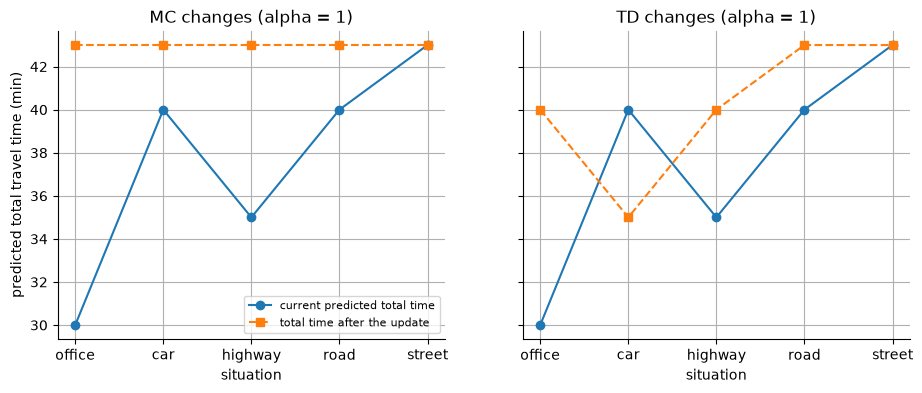

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
total_now = DRIVE_ELAPSED[:-1] + DRIVE_V
for ax, new, title in (
    (ax1, DRIVE_ELAPSED[:-1] + DRIVE_V + mc_error, "MC changes (alpha = 1)"),
    (ax2, DRIVE_ELAPSED[:-1] + DRIVE_V + td_error, "TD changes (alpha = 1)"),
):
    ax.plot(range(5), total_now, "o-", label="current predicted total time")
    ax.plot(range(5), new, "s--", label="total time after the update")
    ax.set(xticks=range(5), xticklabels=["office", "car", "highway", "road", "street"], xlabel="situation", title=title)
ax1.set_ylabel("predicted total travel time (min)")
ax1.legend(loc="lower right", fontsize=8)
plt.show()

### Reading the result

- With $\alpha = 1$ the changes are the errors themselves. TD errors are 10, -5, 5, 3, 0 minutes and MC errors are 13, 3, 8, 3, 0, from leaving the office to entering the home street. Both match the arithmetic of the book's table by hand, including the MC error of 8 at the highway exit and its update of +4 minutes for $\alpha = 1/2$.
- The two methods disagree most at the start of the trip: MC says raise the 30-minute prediction by 13 (to the actual 43), TD says raise it by 10, because it looks only at the next prediction (35 minutes to go after 5 minutes elapsed). At the car TD even lowers the prediction by 5 while MC raises it by 3.
- The TD errors from a step on add up to the MC error of that step (10 - 5 + 5 + 3 + 0 = 13). That is an identity for $\gamma = 1$ and a terminal value of 0, so it is listed as such and not as evidence about the method.
- The online TD(0) loop gives the same changes as the vectorized errors; that confirms the two code paths agree and nothing more.
- On the traffic-jam day the start's estimate can move at minute 25, while the trip is still going: the TD target is 25 elapsed plus 25 expected, 50, and with $\alpha = 1/2$ the estimate moves from 30 to 40. MC would have to wait for the arrival.
- The left plot shows MC pulling every predicted total time to the actual 43; the right plot shows TD pulling each prediction to the next one. The arrows of the book's two figures are these changes; the comparison is by eye and agrees.

## 2. TD(0) against constant-step-size MC on the random walk

Five states in a row, A to E, start in the middle state C. Each step goes left or right with probability $1/2$. An episode ends on leaving at either end, with reward $+1$ for leaving on the right and 0 otherwise. With no discounting the true value of a state is the probability of ending on the right: $\tfrac16, \tfrac26, \tfrac36, \tfrac46, \tfrac56$ for A to E.

- The task is to predict those values from episodes alone, starting from $V(s) = 0.5$ everywhere, with TD(0) and with constant-$\alpha$ MC.
- The error measure is the root-mean-square (RMS) error over the five states, $\sqrt{\tfrac15\sum_s (V(s) - v_\pi(s))^2}$, averaged over 100 runs of 100 episodes.
- The book's step sizes are used: TD $\alpha \in \{0.05, 0.1, 0.15\}$, MC $\alpha \in \{0.01, 0.02, 0.03, 0.04\}$.
- Constant-$\alpha$ MC here is the every-visit rule applied in time order after the episode, with all returns computed first. Because every reward before the exit is 0, all visits of a state within one episode have the same return.
- All seven methods see the same episodes in each run (paired draws), so differences between methods are not caused by different luck.
- The $\pm$ in the tables is the **standard error** of an average over runs: the spread of the quantity across the runs divided by the square root of the number of runs.
- A **z** is an average divided by its own standard error. A **paired z** compares two methods on the same runs: it is the z of their average difference. Values near 0 mean no detectable difference.
- When $m$ comparisons are judged at once, each paired z or standardized error is held to the normal-distribution limit that keeps the chance of any false alarm at 5% (a Bonferroni limit); the limit is printed with each check.

The truth is computed by solving the linear Bellman equation $v = r + Pv$ of the walk (the value of a state is its expected reward plus the expected value of the next state; checked against the closed form), never by the learners.

In [6]:
def walk_run(rng: np.random.Generator, n_episodes: int) -> list:
    """Episodes of the random walk as (visited states, rewards). Draw order: one fair bit per step, 1 means right; start in C."""
    bits, i, episodes = rng.integers(0, 2, CHUNK).tolist(), 0, []
    for _ in range(n_episodes):
        s, path = N_WALK // 2, []
        while 0 <= s < N_WALK:
            path.append(s)
            if i == len(bits):
                bits, i = rng.integers(0, 2, CHUNK).tolist(), 0
            s += 2 * bits[i] - 1
            i += 1
        episodes.append((path, [0.0] * (len(path) - 1) + [float(s == N_WALK)]))
    return episodes


def walk_truth() -> tuple[np.ndarray, float]:
    """Exact values and the expected episode length from C: solve (I - P) v = r and (I - P) t = 1, P moving left or right with probability 1/2, r the chance of exiting right."""
    P = 0.5 * (np.eye(N_WALK, k=1) + np.eye(N_WALK, k=-1))
    r = np.zeros(N_WALK)
    r[-1] = 0.5
    return np.linalg.solve(np.eye(N_WALK) - P, r), float(
        np.linalg.solve(np.eye(N_WALK) - P, np.ones(N_WALK))[N_WALK // 2]
    )


def paired_z(a: np.ndarray, b: np.ndarray) -> tuple[float, float]:
    """Average of a - b over runs and its paired z (the average divided by its standard error)."""
    d = a - b
    return float(d.mean()), float(d.mean() / (d.std(ddof=1) / np.sqrt(len(d))))


def rms_curves(runs: list, update: Callable, alpha: float, truth: np.ndarray) -> np.ndarray:
    """RMS error over states after 0..n episodes for each run (rows), learning online with `update` from V = V_INIT."""
    out = np.empty((len(runs), len(runs[0]) + 1))
    for k, episodes in enumerate(runs):
        V = [V_INIT] * N_WALK
        out[k, 0] = np.sqrt(np.mean((np.array(V) - truth) ** 2))
        for j, (states, rewards) in enumerate(episodes):
            update(V, states, rewards, alpha)
            out[k, j + 1] = np.sqrt(np.mean((np.array(V) - truth) ** 2))
    return out


def bonferroni_z(m: int) -> float:
    """Two-sided normal limit for m simultaneous comparisons at the shared family-wise error rate."""
    return float(stats.norm.isf(FWER / (2 * m)))

In [7]:
rngs = [np.random.default_rng(s) for s in np.random.SeedSequence(SEED_WALK).spawn(WALK_RUNS)]
walk_runs = [walk_run(rng, WALK_EPISODES) for rng in rngs]
v_true, exact_len = walk_truth()
print("Exact values A..E:", np.round(v_true, 4).tolist(), "closed form k/6:", np.allclose(v_true, np.arange(1, 6) / 6))

methods = [(f"TD alpha={a}", td0_episode, a) for a in TD_ALPHAS] + [(f"MC alpha={a}", mc_episode, a) for a in MC_ALPHAS]
curves = {name: rms_curves(walk_runs, update, alpha, v_true) for name, update, alpha in methods}
print(f"{'method':>16}" + "".join(f"{n:>13}" for n in (0, *WALK_CHECK_EPISODES)))
for name, c in curves.items():
    print(
        f"{name:>16}"
        + "".join(
            f"{c[:, n].mean():>7.4f}±{c[:, n].std(ddof=1) / np.sqrt(WALK_RUNS):.3f}" for n in (0, *WALK_CHECK_EPISODES)
        )
    )

Exact values A..E: [0.1667, 0.3333, 0.5, 0.6667, 0.8333] closed form k/6: True
          method            0           10           25           50          100
   TD alpha=0.05 0.2357±0.000 0.1745±0.000 0.1100±0.001 0.0522±0.002 0.0360±0.002
    TD alpha=0.1 0.2357±0.000 0.1281±0.001 0.0564±0.002 0.0513±0.003 0.0547±0.002
   TD alpha=0.15 0.2357±0.000 0.0945±0.002 0.0553±0.003 0.0710±0.003 0.0693±0.003
   MC alpha=0.01 0.2357±0.000 0.2129±0.001 0.1809±0.002 0.1403±0.002 0.0958±0.002
   MC alpha=0.02 0.2357±0.000 0.1974±0.002 0.1507±0.003 0.1034±0.004 0.0834±0.004
   MC alpha=0.03 0.2357±0.000 0.1868±0.003 0.1356±0.004 0.0955±0.005 0.0965±0.005
   MC alpha=0.04 0.2357±0.000 0.1798±0.004 0.1305±0.005 0.1006±0.006 0.1111±0.006


In [8]:
all_paths = [e for run in walk_runs for e in run]
lengths = np.array([len(p) for p, _ in all_paths])
right = np.array([r[-1] for _, r in all_paths])
td_at_truth, mc_at_truth = [[] for _ in range(N_WALK)], [[] for _ in range(N_WALK)]
for path, rew in all_paths:
    V = v_true.tolist()
    for s, r, s2 in zip(path, rew, path[1:] + [None]):
        td_at_truth[s].append(td0_step(V, s, r, s2, NO_UPDATE))
    first = {}
    for s, g in zip(path, episode_returns(rew)):
        first.setdefault(s, g)
    for s, g in first.items():
        mc_at_truth[s].append(g - V[s])
z_td = np.array([np.mean(x) / (np.std(x, ddof=1) / np.sqrt(len(x))) for x in td_at_truth])
z_mc = np.array([np.mean(x) / (np.std(x, ddof=1) / np.sqrt(len(x))) for x in mc_at_truth])
z_len = (lengths.mean() - exact_len) / (lengths.std(ddof=1) / np.sqrt(len(lengths)))
z_right = (right.mean() - v_true[N_WALK // 2]) / np.sqrt(v_true[N_WALK // 2] * (1 - v_true[N_WALK // 2]) / len(right))
z_lim = bonferroni_z(2 * N_WALK + 2)
print(
    f"At the true values the mean TD error per state has z = {np.round(z_td, 2).tolist()} and the mean first-visit MC error z = {np.round(z_mc, 2).tolist()}"
)
print(
    f"Episode length: mean {lengths.mean():.3f} (exact {exact_len:.0f}, z = {z_len:.2f}); share ending right {right.mean():.4f} (exact {v_true[N_WALK // 2]:.1f}, z = {z_right:.2f}); limit {z_lim:.2f}"
)
check(
    f"the simulated walk, the TD error and the first-visit MC error are unbiased at the truth ({2 * N_WALK + 2} comparisons, Bonferroni limit {z_lim:.2f})",
    bool(max(np.abs(z_td).max(), np.abs(z_mc).max(), abs(z_len), abs(z_right)) < z_lim),
)

At the true values the mean TD error per state has z = [-0.83, 0.86, 0.57, 1.04, -1.94] and the mean first-visit MC error z = [-1.09, -0.25, 0.3, 0.57, -0.14]
Episode length: mean 9.040 (exact 9, z = 0.57); share ending right 0.5015 (exact 0.5, z = 0.30); limit 2.87
Checkpoint: the simulated walk, the TD error and the first-visit MC error are unbiased at the truth (12 comparisons, Bonferroni limit 2.87): True


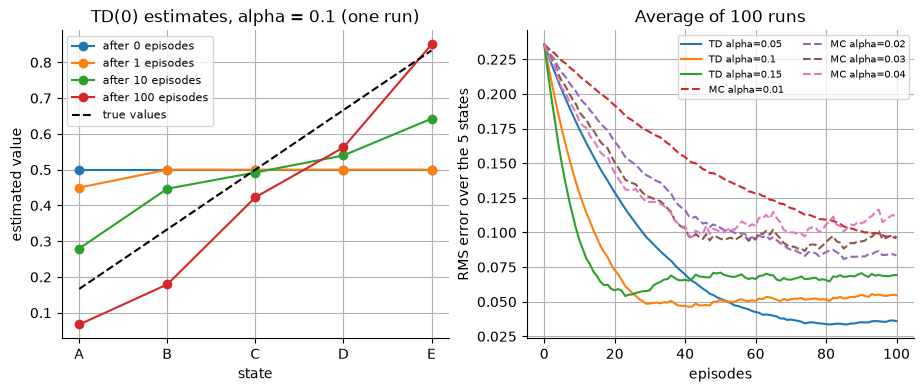

snapshot of the single run: {0: [0.5, 0.5, 0.5, 0.5, 0.5], 1: [0.45, 0.5, 0.5, 0.5, 0.5], 10: [0.28, 0.447, 0.492, 0.54, 0.643], 100: [0.067, 0.179, 0.423, 0.562, 0.85]}


In [9]:
snap_rng = np.random.default_rng(np.random.SeedSequence(SEED_WALK).spawn(WALK_RUNS + 1)[-1])
snap_episodes = walk_run(snap_rng, max(SNAPSHOT_EPISODES))
V = [V_INIT] * N_WALK
snapshots = {0: list(V)}
for j, (states, rewards) in enumerate(snap_episodes, start=1):
    td0_episode(V, states, rewards, SNAPSHOT_ALPHA)
    if j in SNAPSHOT_EPISODES:
        snapshots[j] = list(V)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for n, v in snapshots.items():
    ax1.plot(list("ABCDE"), v, "o-", label=f"after {n} episodes")
ax1.plot(list("ABCDE"), v_true, "k--", label="true values")
ax1.set(xlabel="state", ylabel="estimated value", title=f"TD(0) estimates, alpha = {SNAPSHOT_ALPHA} (one run)")
ax1.legend(fontsize=8)
for name, c in curves.items():
    ax2.plot(c.mean(axis=0), "-" if name.startswith("TD") else "--", label=name)
ax2.set(xlabel="episodes", ylabel="RMS error over the 5 states", title=f"Average of {WALK_RUNS} runs")
ax2.legend(fontsize=7, ncol=2)
plt.show()
print("snapshot of the single run:", {n: np.round(v, 3).tolist() for n, v in snapshots.items()})

In [10]:
best_td = min((n for n in curves if n.startswith("TD")), key=lambda n: curves[n][:, 1:].mean())
best_mc = min((n for n in curves if n.startswith("MC")), key=lambda n: curves[n][:, 1:].mean())
z_cut = bonferroni_z(len(WALK_CHECK_EPISODES))
gaps = {}
print(
    f"Best TD {best_td} and best MC {best_mc} by mean error over episodes 1..{WALK_EPISODES} (selected on the same runs, so slightly optimistic for both)"
)
for n in WALK_CHECK_EPISODES:
    gaps[n] = paired_z(curves[best_mc][:, n], curves[best_td][:, n])
    print(f"  after {n:>3} episodes: MC - TD = {gaps[n][0]:.4f} (paired z = {gaps[n][1]:.1f})")
pair_z = {}
for n in (WALK_CHECK_EPISODES[0], WALK_EPISODES):
    pair_z[n] = np.array(
        [
            [paired_z(curves[f"MC alpha={m}"][:, n], curves[f"TD alpha={a}"][:, n])[1] for m in MC_ALPHAS]
            for a in TD_ALPHAS
        ]
    )
    print(f"Paired z of (MC - TD) after {n} episodes, rows TD alpha {TD_ALPHAS}, columns MC alpha {MC_ALPHAS}:")
    print(np.round(pair_z[n], 1))
z_grid = bonferroni_z(len(TD_ALPHAS) * len(MC_ALPHAS))
check(
    f"TD (best alpha) beats MC (best alpha) at every compared episode count by more than {z_cut:.2f} paired standard errors",
    all(g > 0 and z > z_cut for g, z in gaps.values()),
)
check(
    f"after {WALK_EPISODES} episodes every one of the {pair_z[WALK_EPISODES].size} TD step sizes is below every MC step size (paired z above {z_grid:.2f})",
    bool((pair_z[WALK_EPISODES] > z_grid).all()),
)

Best TD TD alpha=0.1 and best MC MC alpha=0.03 by mean error over episodes 1..100 (selected on the same runs, so slightly optimistic for both)
  after  10 episodes: MC - TD = 0.0587 (paired z = 20.8)
  after  25 episodes: MC - TD = 0.0792 (paired z = 22.5)
  after  50 episodes: MC - TD = 0.0442 (paired z = 10.3)
  after 100 episodes: MC - TD = 0.0418 (paired z = 8.2)
Paired z of (MC - TD) after 10 episodes, rows TD alpha (0.05, 0.1, 0.15), columns MC alpha (0.01, 0.02, 0.03, 0.04):
[[41.3 11.5  4.   1.3]
 [83.5 38.4 20.8 13.5]
 [74.3 55.3 35.8 24.7]]
Paired z of (MC - TD) after 100 episodes, rows TD alpha (0.05, 0.1, 0.15), columns MC alpha (0.01, 0.02, 0.03, 0.04):
[[29.8 12.4 11.8 12.6]
 [16.7  7.3  8.2  9.5]
 [ 9.2  3.5  5.4  7.1]]
Checkpoint: TD (best alpha) beats MC (best alpha) at every compared episode count by more than 2.50 paired standard errors: True
Checkpoint: after 100 episodes every one of the 12 TD step sizes is below every MC step size (paired z above 2.87): True


### Reading the result

- **Truth and simulator.** The linear solve gives 0.1667, 0.3333, 0.5, 0.6667, 0.8333, equal to $k/6$. At these true values the average TD error and the average first-visit MC error of every state are indistinguishable from 0 (largest $|z|$ 1.94, below the limit of 2.87 for 12 comparisons), the simulated episode length averages 9.040 steps (exact 9) and 0.5015 of the episodes end on the right (exact 0.5). So the walk, the TD error and the first-visit MC error behave as the exact model says. The learner uses the every-visit MC rule, whose returns are the same numbers (all visits of a state in an episode share one return) but which weights episodes by their number of visits; that weighting is not tested separately.
- **Learning curves.** After 100 episodes the average RMS error is 0.0360, 0.0547 and 0.0693 for TD with $\alpha = 0.05, 0.1, 0.15$, and 0.0958, 0.0834, 0.0965 and 0.1111 for MC with $\alpha = 0.01, 0.02, 0.03, 0.04$ (standard errors between 0.002 and 0.006).
- **TD is better.** The best TD step size by average error over the 100 episodes is 0.1 and the best MC step size is 0.03 (both chosen on the same runs, which flatters both slightly). MC minus TD is 0.0587, 0.0792, 0.0442 and 0.0418 after 10, 25, 50 and 100 episodes, with paired z of 20.8, 22.5, 10.3 and 8.2, all above the limit of 2.50. After 100 episodes every one of the 12 TD and MC step-size pairs favors TD (smallest paired z 3.5, limit 2.87).
- **Not a finding.** After 10 episodes TD with $\alpha = 0.05$ (0.1745) and MC with $\alpha = 0.04$ (0.1798) are not distinguishable (paired z 1.3): a small TD step size is slow early.
- **Constant $\alpha$ keeps fluctuating.** TD with $\alpha = 0.15$ reaches 0.0553 after 25 episodes but is at 0.0710 after 50 and 0.0693 after 100: with $\alpha = 0.1$ (0.0564, 0.0513, 0.0547 after 25, 50 and 100 episodes) and $\alpha = 0.15$ it levels off at an error floor, and the floor is higher for the larger step size; with $\alpha = 0.05$ the curve is still falling at 100 episodes (0.0522 after 50, 0.0360 after 100), so its floor is not reached. In the single run of the left plot with $\alpha = 0.1$, the estimates after 100 episodes (0.067, 0.179, 0.423, 0.562, 0.85) are near but not on the true values, and only the state before the exit moved after the first episode (A from 0.5 to 0.45).
- **Book.** By eye the shapes agree with the book's figures: TD curves fall fast and level off, MC curves fall slowly, the largest TD step size ends highest and has a minimum before the end, and the TD curves lie below the MC curves. The levels after 100 episodes (TD about 0.04 to 0.07, MC about 0.08 to 0.11) are in the range of the book's plot; the reading is by eye.

## 3. Batch updating and the certainty-equivalence estimate

With a finite amount of experience, one can present it again and again. In **batch updating** the increments of one pass over all the data are summed and applied once, and passes repeat until the values stop changing. With a small enough step size, TD(0) and constant-$\alpha$ MC each converge to one answer that does not depend on $\alpha$, but the two answers differ.

- **Batch MC** (every-visit, as everywhere in this notebook) ends at the sample average of the returns that followed each visit of a state, which minimizes the squared error on the training returns.
- **Batch TD(0)** ends at the **certainty-equivalence estimate**: build the maximum-likelihood model of the data (each transition probability is the fraction of observed transitions from $i$ that went to $j$, each expected reward the average observed reward on them) and compute the values that are exactly right for that model, $\hat v = \hat r + \hat P \hat v$.
- Here the experiment of the book: after each new episode, all episodes so far are one batch, trained to convergence, and compared with the truth, over 100 runs of 100 episodes.

For speed all runs are trained together and the sums of increments are computed from counts: transitions $N_{ij}$, rewards $R_i$, visits $n_i$ and summed returns $\Sigma G_i$ (one column of $N$ for the terminal state). One batch pass is then

$$
\Delta V_i = \alpha\Big(R_i + \sum_j N_{ij} V_j - n_i V_i\Big) \;(\text{TD}), \qquad \Delta V_i = \alpha\Big(\Sigma G_i - n_i V_i\Big) \;(\text{MC}).
$$

- Where this differs from the book: the step size is set per batch as `BATCH_STEP_SCALE` divided by the largest visit count, which is small enough to be stable and converge, and each batch starts from the values of the previous one instead of from 0.5. The limit should not depend on either choice; one cold start from 0.5 with a four times smaller step size checks that.
- A state that has never been visited keeps 0.5 in both methods and in the certainty-equivalence estimate.
- The certainty-equivalence estimate and the sample averages are computed from the raw episode lists by separate code, so agreeing with the batch iteration is a real check.
- The tolerance for that agreement is derived, not guessed. The batch loop stops when no increment exceeds `BATCH_TOL`; the increment still pending at the stopping point is $\alpha M(V^* - V)$ with $M = \mathrm{diag}(n) - N$, so the distance to the exact answer $V^*$ is at most the size of the pending increment divided by $\alpha$ times the smallest singular value of $M$ (a measure of how close the matrix is to being singular; for MC, by $\alpha n_i$ per state). Each run's gap must lie under its own bound, plus a small allowance for the rounding of the linear solve.

In [11]:
def episode_stats(states: list, rewards: list, n_states: int) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Transition counts N[i, j] (last column: terminal), reward sums R[i] and return sums G[i] of one episode."""
    N, R, G = np.zeros((n_states, n_states + 1)), np.zeros(n_states), np.zeros(n_states)
    for s, s_next, r, g in zip(states, states[1:] + [n_states], rewards, episode_returns(rewards)):
        N[s, s_next] += 1
        R[s] += r
        G[s] += g
    return N, R, G


def batch_td(N: np.ndarray, R: np.ndarray, V: np.ndarray, alpha: np.ndarray) -> tuple[np.ndarray, np.ndarray, int]:
    """Batch TD(0): repeat summed increments until the largest is below BATCH_TOL. Returns V, the increment still pending at V, and the passes used."""
    n, P = N.sum(-1), N[..., :-1]
    for passes in range(MAX_PASSES):
        delta = alpha * (R + np.einsum("...ij,...j->...i", P, V) - n * V)
        if np.abs(delta).max() < BATCH_TOL:
            return V, delta, passes
        V = V + delta
    raise RuntimeError("batch TD(0) did not converge")


def batch_mc(n: np.ndarray, G: np.ndarray, V: np.ndarray, alpha: np.ndarray) -> tuple[np.ndarray, np.ndarray, int]:
    """Batch constant-alpha MC: repeat summed increments until the largest is below BATCH_TOL. Returns V, the pending increment and the passes."""
    for passes in range(MAX_PASSES):
        delta = alpha * (G - n * V)
        if np.abs(delta).max() < BATCH_TOL:
            return V, delta, passes
        V = V + delta
    raise RuntimeError("batch MC did not converge")

In [12]:
def certainty_equivalence(
    episodes: list, n_states: int, v_unseen: np.ndarray
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Maximum-likelihood model from the raw episodes, then its exact values. Returns values, transition matrix P-hat (nonterminal part) and r-hat."""
    count, visits, reward = np.zeros((n_states, n_states)), np.zeros(n_states), np.zeros(n_states)
    for states, rewards in episodes:
        for t, (s, r) in enumerate(zip(states, rewards)):
            visits[s] += 1
            reward[s] += r
            if t + 1 < len(states):
                count[s, states[t + 1]] += 1
    seen = visits > 0
    P, r_hat = count / np.maximum(visits, 1)[:, None], reward / np.maximum(visits, 1)
    A, b = np.eye(n_states) - P, r_hat.copy()
    A[~seen], b[~seen] = np.eye(n_states)[~seen], v_unseen[~seen]
    return np.linalg.solve(A, b), P, r_hat


def sample_averages(episodes: list, n_states: int, v_unseen: np.ndarray) -> np.ndarray:
    """Average of the returns that followed every visit of each state (every-visit); unvisited states keep `v_unseen`."""
    total, visits = np.zeros(n_states), np.zeros(n_states)
    for states, rewards in episodes:
        for s, g in zip(states, episode_returns(rewards)):
            total[s] += g
            visits[s] += 1
    return np.where(visits > 0, total / np.maximum(visits, 1), v_unseen)


def pending_bound(N: np.ndarray, alpha: np.ndarray, delta: np.ndarray) -> np.ndarray:
    """Upper bound on the distance of batch TD's V from its fixed point: the pending increment is alpha M (V* - V) with M = diag(n) - N, so the distance is at most |increment| / (alpha sigma_min(M))."""
    M = np.zeros_like(N[..., :-1])
    M += np.eye(M.shape[-1]) * N.sum(-1)[..., None] - N[..., :-1]
    M += np.eye(M.shape[-1]) * (N.sum(-1) == 0)[..., None]
    return np.linalg.norm(delta, axis=-1) / (alpha[..., 0] * np.linalg.svd(M, compute_uv=False)[..., -1])

In [13]:
rngs = [np.random.default_rng(s) for s in np.random.SeedSequence(SEED_BATCH).spawn(BATCH_RUNS)]
batch_runs = [walk_run(rng, BATCH_EPISODES) for rng in rngs]
ep_stats = [[episode_stats(s, r, N_WALK) for s, r in run] for run in batch_runs]
N_cum, R_cum, G_cum = (np.cumsum(np.array([[st[i] for st in run] for run in ep_stats]), axis=1) for i in range(3))
v_true, _ = walk_truth()

In [14]:
V_td = np.full((BATCH_RUNS, N_WALK), V_INIT)
V_mc = V_td.copy()
err_td, err_mc = np.zeros((BATCH_RUNS, BATCH_EPISODES + 1)), np.zeros((BATCH_RUNS, BATCH_EPISODES + 1))
err_td[:, 0] = err_mc[:, 0] = np.sqrt(np.mean((V_INIT - v_true) ** 2))
saved, pass_td, pass_mc = {}, [], []
for k in range(1, BATCH_EPISODES + 1):
    N, R, G = N_cum[:, k - 1], R_cum[:, k - 1], G_cum[:, k - 1]
    n = N.sum(-1)
    alpha = BATCH_STEP_SCALE / n.max(axis=-1, keepdims=True)
    V_td, pend_td, p1 = batch_td(N, R, V_td, alpha)
    V_mc, pend_mc, p2 = batch_mc(n, G, V_mc, alpha)
    pass_td.append(p1)
    pass_mc.append(p2)
    err_td[:, k] = np.sqrt(np.mean((V_td - v_true) ** 2, axis=1))
    err_mc[:, k] = np.sqrt(np.mean((V_mc - v_true) ** 2, axis=1))
    if k in WALK_CHECK_EPISODES:
        saved[k] = (N, R, n, alpha, V_td, pend_td, V_mc, pend_mc)

In [15]:
agree = {}
for k, (N, R, n, alpha, V_td_k, pend_td, V_mc_k, pend_mc) in saved.items():
    ce = np.array([certainty_equivalence(run[:k], N_WALK, np.full(N_WALK, V_INIT))[0] for run in batch_runs])
    avg = np.array([sample_averages(run[:k], N_WALK, np.full(N_WALK, V_INIT)) for run in batch_runs])
    gap_td, gap_mc = np.linalg.norm(V_td_k - ce, axis=1), np.linalg.norm(V_mc_k - avg, axis=1)
    bound_td = pending_bound(N, alpha, pend_td) + ROUNDING_TOL
    bound_mc = np.linalg.norm(pend_mc, axis=1) / (alpha[:, 0] * np.maximum(n.min(axis=1), 1)) + ROUNDING_TOL
    agree[k] = (
        gap_td.max(),
        bound_td.max(),
        gap_mc.max(),
        bound_mc.max(),
        bool((gap_td <= bound_td).all() and (gap_mc <= bound_mc).all()),
    )
alpha_cold = alpha / COLD_STEP_DIVISOR
V_cold, pend_cold, _ = batch_td(N, R, np.full((BATCH_RUNS, N_WALK), V_INIT), alpha_cold)
gap_cold = np.linalg.norm(V_cold - ce, axis=1)
bound_cold = pending_bound(N, alpha_cold, pend_cold) + ROUNDING_TOL

print(
    f"Passes to converge per batch: TD median {int(np.median(pass_td))}, max {max(pass_td)}; MC median {int(np.median(pass_mc))}, max {max(pass_mc)}"
)
print(f"{'episodes':>9}{'TD vs certainty-equivalence':>30}{'MC vs sample average':>28}")
for k, (g1, b1, g2, b2, _) in agree.items():
    print(f"{k:>9}{g1:>15.2e} (bound {b1:.1e}){g2:>12.2e} (bound {b2:.1e})")
print(
    f"Cold start from {V_INIT} with a {COLD_STEP_DIVISOR} times smaller step size after {WALK_CHECK_EPISODES[-1]} episodes: largest gap {gap_cold.max():.2e} (bound {bound_cold.max():.1e})"
)
check(
    "batch TD(0) reaches the certainty-equivalence estimate and batch MC the sample averages, in every run, within the derived bounds",
    all(a[4] for a in agree.values()),
)
check(
    f"batch TD(0) started from {V_INIT} with a {COLD_STEP_DIVISOR} times smaller step size reaches the same estimate within its bound (the limit does not depend on the step size or the start)",
    (gap_cold <= bound_cold).all(),
)

Passes to converge per batch: TD median 660, max 4609; MC median 195, max 919
 episodes   TD vs certainty-equivalence        MC vs sample average
       10       1.12e-10 (bound 2.1e-10)    1.55e-11 (bound 1.2e-10)
       25       7.08e-11 (bound 1.7e-10)    1.32e-11 (bound 1.1e-10)
       50       6.34e-11 (bound 1.7e-10)    8.24e-12 (bound 1.1e-10)
      100       6.10e-11 (bound 1.6e-10)    7.02e-12 (bound 1.1e-10)
Cold start from 0.5 with a 4 times smaller step size after 100 episodes: largest gap 2.46e-10 (bound 3.6e-10)
Checkpoint: batch TD(0) reaches the certainty-equivalence estimate and batch MC the sample averages, in every run, within the derived bounds: True
Checkpoint: batch TD(0) started from 0.5 with a 4 times smaller step size reaches the same estimate within its bound (the limit does not depend on the step size or the start): True


 episodes      batch TD      batch MC  MC - TD paired z
        1  0.4032±0.0086  0.4032±0.0086   0.0000      nan
        2  0.2939±0.0169  0.3466±0.0124   0.0527      6.6
        5  0.2054±0.0142  0.2512±0.0128   0.0457      5.3
       10  0.1416±0.0088  0.1770±0.0092   0.0354      5.0
       25  0.0847±0.0049  0.1249±0.0055   0.0402      9.0
       50  0.0580±0.0037  0.0842±0.0041   0.0262      6.6
       75  0.0504±0.0032  0.0681±0.0036   0.0177      5.7
      100  0.0419±0.0026  0.0599±0.0029   0.0180      6.7
Checkpoint: batch TD(0) beats batch MC by more than 2.50 paired standard errors at every compared episode count: True
Smallest paired z over the batch sizes 2 to 100: 4.0 at 11 episodes (limit 3.48)
Checkpoint: batch TD(0) is below batch MC at every batch size from 2 to 100 episodes (every paired z above 3.48): True


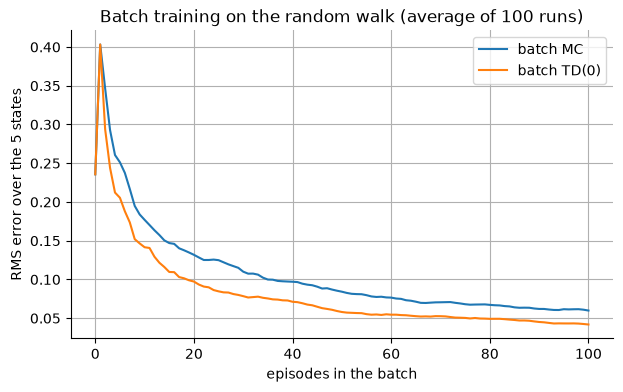

In [16]:
print(f"{'episodes':>9}{'batch TD':>14}{'batch MC':>14}{'MC - TD':>9}{'paired z':>9}")
for k in TABLE_EPISODES:
    gap, z = (
        paired_z(err_mc[:, k], err_td[:, k])
        if np.abs(err_mc[:, k] - err_td[:, k]).max() > IDENTICAL_TOL
        else (0.0, float("nan"))
    )
    se_td, se_mc = (e[:, k].std(ddof=1) / np.sqrt(BATCH_RUNS) for e in (err_td, err_mc))
    print(f"{k:>9}{err_td[:, k].mean():>8.4f}±{se_td:.4f}{err_mc[:, k].mean():>8.4f}±{se_mc:.4f}{gap:>9.4f}{z:>9.1f}")
batch_z = {k: paired_z(err_mc[:, k], err_td[:, k]) for k in WALK_CHECK_EPISODES}
check(
    f"batch TD(0) beats batch MC by more than {z_cut:.2f} paired standard errors at every compared episode count",
    all(g > 0 and z > z_cut for g, z in batch_z.values()),
)
sizes = range(2, BATCH_EPISODES + 1)
sizes_z = np.array([paired_z(err_mc[:, k], err_td[:, k]) for k in sizes])
z_sizes = bonferroni_z(len(sizes))
print(
    f"Smallest paired z over the batch sizes 2 to {BATCH_EPISODES}: {sizes_z[:, 1].min():.1f} at {sizes[int(sizes_z[:, 1].argmin())]} episodes (limit {z_sizes:.2f})"
)
check(
    f"batch TD(0) is below batch MC at every batch size from 2 to {BATCH_EPISODES} episodes (every paired z above {z_sizes:.2f})",
    (sizes_z[:, 1] > z_sizes).all(),
)

plt.plot(err_mc.mean(axis=0), label="batch MC")
plt.plot(err_td.mean(axis=0), label="batch TD(0)")
plt.xlabel("episodes in the batch")
plt.ylabel("RMS error over the 5 states")
plt.title(f"Batch training on the random walk (average of {BATCH_RUNS} runs)")
plt.legend()
plt.show()

### Reading the result

- **Convergence is to the stated answers.** In all 100 runs, at 10, 25, 50 and 100 episodes, batch TD(0) is within its derived bound of the certainty-equivalence estimate (largest gap 1.12e-10 against a bound of 2.1e-10 at 10 episodes, and 6.10e-11 against 1.6e-10 at 100) and batch MC is within its bound of the sample averages (largest gap 1.55e-11 against 1.2e-10 at 10 episodes, 7.02e-12 against 1.1e-10 at 100). A batch needs a median of 660 passes for TD (at most 4609) and 195 for MC (at most 919).
- **Batch TD is better.** After 1 episode the two give the same error, 0.4032 (equal to the printed precision; both give the one episode's return to every visited state, which is not tested separately). After 2 episodes TD has 0.2939 and MC 0.3466. After 10, 25, 50 and 100 episodes the errors are 0.1416 against 0.1770, 0.0847 against 0.1249, 0.0580 against 0.0842 and 0.0419 against 0.0599 for TD and MC, with paired z of 5.0, 9.0, 6.6 and 6.7, all above the limit of 2.50. The average batch TD error is below the average batch MC error at every batch size from 2 to 100.
- **Step size and start do not matter.** Started from 0.5 with a four times smaller step size, batch TD(0) after 100 episodes is again within its bound of the certainty-equivalence estimate (largest gap 2.46e-10 against a bound of 3.6e-10).
- **Plot.** The plot shows both average errors falling with the batch size, with the TD curve below the MC curve throughout.
- **Why:** batch MC fits the returns it has seen, while batch TD uses the structure of the process (each state moves to a neighbor). The next section isolates this difference.
- **Gap over time.** The difference MC minus TD shrinks from 0.0527 after 2 episodes to 0.0180 after 100; only the ratio of the two errors stays roughly the same (TD about 0.7 of MC from 25 episodes on: 0.0847 against 0.1249, 0.0419 against 0.0599).
- **Book.** The ordering and the shapes agree with the book's batch figure by eye. The book's curves end near 0.05 (MC) and 0.035 (TD) by eye, here 0.0599 and 0.0419, higher by about 0.01 and 0.007, which is two to three of the standard errors printed (0.003); sampling noise and reading the figure by eye are possible explanations; neither is tested. Whether first-visit instead of every-visit MC would lower the MC level is not tested here.

## 4. You are the predictor

Eight episodes of an unknown two-state process are observed: once A, then B, with reward 0 each time; then B alone seven times, with reward 1 six times and 0 once. What should $V(\mathsf{A})$ and $V(\mathsf{B})$ be?

- Both methods agree on $V(\mathsf{B}) = 3/4$: six of the eight times B ended with return 1.
- Batch MC has seen A once, followed by return 0, so it says $V(\mathsf{A}) = 0$: zero error on the data.
- Batch TD(0) uses the model: A always goes to B, so $V(\mathsf{A}) = V(\mathsf{B}) = 3/4$.

A process is **Markov** when the next state and reward depend only on the current state. The section runs the batch methods from several step sizes and starting values (the answer should not depend on them), prints the maximum-likelihood model and its exact values, and then tests the claim that TD's answer is better on future data when the process is Markov. The test draws many data sets of the same shape (one episode through A, seven from B) from a process where B ends with reward 1 with probability $3/4$, and compares the squared error of each method's $V(\mathsf{A})$ against the truth $3/4$.

In [17]:
rng = np.random.default_rng(SEED_PRED)
N_p, R_p, G_p = (sum(x) for x in zip(*[episode_stats(s, r, 2) for s, r in PRED_EPISODES]))
n_p = N_p.sum(-1)
results = {}
for alpha in PRED_ALPHAS:
    for init in PRED_INITS:
        a = np.array([alpha])
        results[(alpha, init)] = (
            batch_td(N_p, R_p, np.full(2, init), a)[0],
            batch_mc(n_p, G_p, np.full(2, init), a)[0],
        )
td_vals = np.array([v[0] for v in results.values()])
mc_vals = np.array([v[1] for v in results.values()])

In [18]:
ce_v, P_hat, r_hat = certainty_equivalence(PRED_EPISODES, 2, np.zeros(2))
avg_v = sample_averages(PRED_EPISODES, 2, np.zeros(2))
print(
    f"Maximum-likelihood model: P(A to B) = {P_hat[0, 1]:.2f}, P(B to terminal) = {1 - P_hat[1].sum():.2f}, expected reward from A = {r_hat[0]:.2f}, from B = {r_hat[1]:.2f}"
)
print(
    f"Certainty-equivalence values: V(A) = {ce_v[0]:.3f}, V(B) = {ce_v[1]:.3f}; sample averages of returns: V(A) = {avg_v[0]:.3f}, V(B) = {avg_v[1]:.3f}"
)
print(
    f"Batch TD(0) over {len(results)} (alpha, start) pairs: V(A) in [{td_vals[:, 0].min():.6f}, {td_vals[:, 0].max():.6f}], V(B) in [{td_vals[:, 1].min():.6f}, {td_vals[:, 1].max():.6f}]"
)
print(
    f"Batch MC over the same pairs: V(A) in [{mc_vals[:, 0].min():.6f}, {mc_vals[:, 0].max():.6f}], V(B) in [{mc_vals[:, 1].min():.6f}, {mc_vals[:, 1].max():.6f}]"
)
returns_seen = {0: [0.0], 1: [0.0] + [1.0] * 6 + [0.0]}


def training_error(v: np.ndarray) -> float:
    """Squared error of the values `v` on the nine returns of the observed data."""
    return float(sum((g - v[s]) ** 2 for s, gs in returns_seen.items() for g in gs))


print(
    f"Squared error on the 9 training returns: batch MC {training_error(mc_vals[0]):.4f}, batch TD(0) {training_error(td_vals[0]):.4f}"
)

pred_tol = (
    2 * BATCH_TOL / min(PRED_ALPHAS)
)  # pending increment over alpha times sigma_min(M), which is 0.99 for these two states
check(
    f"both methods give V(B) = 3/4 and the book's V(A) answers (TD 3/4, MC 0), from every step size and start, within {pred_tol:.0e}",
    max(np.abs(td_vals - PRED_P_RIGHT).max(), np.abs(mc_vals[:, 1] - PRED_P_RIGHT).max(), np.abs(mc_vals[:, 0]).max())
    < pred_tol,
)
check(
    f"the explicit maximum-likelihood model gives V(A) = V(B) = 3/4 and the sample averages give (0, 3/4), within {ROUNDING_TOL:.0e}",
    max(np.abs(ce_v - PRED_P_RIGHT).max(), np.abs(avg_v - [0, PRED_P_RIGHT]).max()) < ROUNDING_TOL,
)

Maximum-likelihood model: P(A to B) = 1.00, P(B to terminal) = 1.00, expected reward from A = 0.00, from B = 0.75
Certainty-equivalence values: V(A) = 0.750, V(B) = 0.750; sample averages of returns: V(A) = 0.000, V(B) = 0.750
Batch TD(0) over 9 (alpha, start) pairs: V(A) in [0.750000, 0.750000], V(B) in [0.750000, 0.750000]
Batch MC over the same pairs: V(A) in [0.000000, 0.000000], V(B) in [0.750000, 0.750000]
Squared error on the 9 training returns: batch MC 1.5000, batch TD(0) 2.0625
Checkpoint: both methods give V(B) = 3/4 and the book's V(A) answers (TD 3/4, MC 0), from every step size and start, within 2e-10: True
Checkpoint: the explicit maximum-likelihood model gives V(A) = V(B) = 3/4 and the sample averages give (0, 3/4), within 1e-10: True


In [19]:
outcomes = (
    rng.random((PRED_DATASETS, len(PRED_EPISODES))) < PRED_P_RIGHT
)  # column 0 is the B exit of the episode that passed through A
mc_a, td_a = outcomes[:, 0].astype(float), outcomes.mean(axis=1)
se_mc, se_td = (mc_a - PRED_P_RIGHT) ** 2, (td_a - PRED_P_RIGHT) ** 2
exact_mc, exact_td = PRED_P_RIGHT * (1 - PRED_P_RIGHT), PRED_P_RIGHT * (1 - PRED_P_RIGHT) / len(PRED_EPISODES)
diff = se_mc - se_td
subset_ok = True
for i in range(PRED_EXACT_CHECK):
    eps_i = [([0, 1], [0.0, float(outcomes[i, 0])])] + [([1], [float(o)]) for o in outcomes[i, 1:]]
    subset_ok &= bool(
        np.isclose(certainty_equivalence(eps_i, 2, np.zeros(2))[0][0], td_a[i], atol=ROUNDING_TOL)
        and np.isclose(sample_averages(eps_i, 2, np.zeros(2))[0], mc_a[i], atol=ROUNDING_TOL)
    )
print(
    f"Squared error of V(A) over {PRED_DATASETS} data sets: batch MC {se_mc.mean():.4f}±{se_mc.std(ddof=1) / np.sqrt(PRED_DATASETS):.4f} (exact p(1-p) = {exact_mc:.4f}), batch TD {se_td.mean():.4f}±{se_td.std(ddof=1) / np.sqrt(PRED_DATASETS):.4f} (exact p(1-p)/{len(PRED_EPISODES)} = {exact_td:.4f})"
)
z_pred = diff.mean() / (diff.std(ddof=1) / np.sqrt(PRED_DATASETS))
print(f"Paired difference MC - TD = {diff.mean():.4f} (exact {exact_mc - exact_td:.4f}), z = {z_pred:.1f}")
z_mse = [
    (se_mc.mean() - exact_mc) / (se_mc.std(ddof=1) / np.sqrt(PRED_DATASETS)),
    (se_td.mean() - exact_td) / (se_td.std(ddof=1) / np.sqrt(PRED_DATASETS)),
]
z_lim2 = bonferroni_z(PAIR)
check(
    f"the simulated errors match the closed forms (z = {z_mse[0]:.2f}, {z_mse[1]:.2f}; limit {z_lim2:.2f})",
    bool(max(abs(z_mse[0]), abs(z_mse[1])) < z_lim2),
)
check(
    f"the shortcut formulas for the two V(A) equal the exact model and sample-average routes on {PRED_EXACT_CHECK} data sets",
    subset_ok,
)
check(
    "TD's V(A) has lower squared error on future data when the process is Markov (z above the limit)",
    bool(z_pred > z_lim2 and diff.mean() > 0),
)

Squared error of V(A) over 20000 data sets: batch MC 0.1870±0.0015 (exact p(1-p) = 0.1875), batch TD 0.0231±0.0002 (exact p(1-p)/8 = 0.0234)
Paired difference MC - TD = 0.1639 (exact 0.1641), z = 107.6
Checkpoint: the simulated errors match the closed forms (z = -0.31, -1.49; limit 2.24): True
Checkpoint: the shortcut formulas for the two V(A) equal the exact model and sample-average routes on 200 data sets: True
Checkpoint: TD's V(A) has lower squared error on future data when the process is Markov (z above the limit): True


### Reading the result

- **The two answers.** The maximum-likelihood model says A always goes to B with reward 0, and B ends with probability 1 with expected reward 0.75. Its exact values are $V(\mathsf{A}) = V(\mathsf{B}) = 0.750$, which is also what batch TD(0) reaches. The sample averages of the observed returns are $V(\mathsf{A}) = 0.000$ and $V(\mathsf{B}) = 0.750$, which is what batch MC reaches. This matches the book.
- **Independent of step size and start.** Over the nine pairs of step size and starting values the batch answers are the same to six decimals (TD: 0.750000 for both states; MC: 0.000000 for A, 0.750000 for B).
- **MC fits the data better.** The squared error summed over the nine training returns is 1.5000 for batch MC and 2.0625 for batch TD(0): MC is the best fit to the data it has seen, as the book says.
- **TD is better on future data, if the process is Markov.** Over 20,000 simulated data sets of the same shape, drawn from a process where B ends with reward 1 with probability 0.75, the mean squared error of $V(\mathsf{A})$ is 0.1870 for batch MC (closed form 0.1875) and 0.0231 for batch TD (closed form 0.0234). The paired difference is 0.1639 (closed form 0.1641), $z = 107.6$. The simulated errors match their closed forms (z of -0.31 and -1.49, limit 2.24).
- This check assumes the process really is the Markov one drawn here; the book makes the same conditional claim. How batch TD and MC compare when the process is not Markov is not tested. The data-set design (one episode through A, seven from B, success probability 0.75) is invented here for the test; the book only describes the one observed data set.

## 5. Sarsa on the windy gridworld

A $7 \times 10$ grid with a start $(3, 0)$ (row, column, rows counted from the top), a goal $(3, 7)$ and an upward wind of 0, 0, 0, 1, 1, 1, 2, 2, 1, 0 cells in the columns. The actions are up, down, right and left. After a move, the cell reached is shifted up by the wind of the column the agent was in; moves off the grid stay inside it. Reward is $-1$ per step until the goal, undiscounted.

**Sarsa** learns action values $Q(s, a)$ of the policy it follows, which is $\varepsilon$-greedy (a uniformly random action with probability $\varepsilon$, otherwise one with the highest $Q$) and so keeps changing as $Q$ changes:

$$
Q(S_t, A_t) \leftarrow Q(S_t, A_t) + \alpha\big[R_{t+1} + \gamma Q(S_{t+1}, A_{t+1}) - Q(S_t, A_t)\big]
$$

- The update uses the quintuple $(S_t, A_t, R_{t+1}, S_{t+1}, A_{t+1})$, hence the name; $Q$ of the terminal state is 0.
- Sarsa is **on-policy**: it learns the values of the very policy that generates its actions, so exploration changes what it learns. (Q-learning, in the next section, is off-policy.)
- As in the book: $\varepsilon = 0.1$, $\alpha = 0.5$, $Q = 0$ initially.
- The book leaves the tie-break open: among actions with the same highest $Q$ the agent picks uniformly at random (at the start all four tie).
- The book's picture counts episodes against time steps in one run; here 100 runs are averaged and each runs for 8000 time steps (an episode in progress at the cutoff is not counted).
- Added here, not in the book: ten long runs (100,000 steps) with $\alpha = 0.1$ and with $\alpha = 0.5$, and ten 8000-step runs with $\alpha = 0.1$, to separate the effect of training duration from that of the step size.

Truths from other routes: the shortest path found by breadth-first search (it explores every cell one step away, then two steps, and so on, so the first arrival at the goal is the fewest steps; the book says 15), the optimal action values by value iteration (the Bellman optimality equation applied again and again until nothing changes), and, because Sarsa follows $\varepsilon$-greedy behavior, the values of the best $\varepsilon$-greedy policy by value iteration with the exploration built in. The expected episode length of that policy is the number the late episodes should approach.

In [20]:
def grid_world(
    shape: tuple, wind: tuple, start: tuple, goal: tuple, cliff: tuple = ()
) -> tuple[np.ndarray, np.ndarray, int, int]:
    """Tables next_state[s, a] and reward[s, a] with s = row * columns + column. The wind of the current column lifts the cell reached;
    a move into a cliff cell costs CLIFF_PENALTY and returns to the start. Returns the tables, the start state and the goal state."""
    rows, cols = shape
    nxt, rew = np.empty((rows * cols, N_ACTIONS), dtype=int), np.full((rows * cols, N_ACTIONS), -1.0)
    for r in range(rows):
        for c in range(cols):
            for a, (dr, dc) in enumerate(MOVES):
                r2, c2 = min(max(r + dr - wind[c], 0), rows - 1), min(max(c + dc, 0), cols - 1)
                if (r2, c2) in cliff:
                    nxt[r * cols + c, a], rew[r * cols + c, a] = start[0] * cols + start[1], CLIFF_PENALTY
                else:
                    nxt[r * cols + c, a] = r2 * cols + c2
    return nxt, rew, start[0] * cols + start[1], goal[0] * cols + goal[1]


def uniform_stream(rng: np.random.Generator):
    """Endless iterator of uniform random numbers."""
    while True:
        yield from rng.random(CHUNK).tolist()

In [21]:
def td_control(
    env: tuple,
    rng: np.random.Generator,
    eps: float,
    alpha: float,
    q_learning: bool = False,
    max_steps: int = 10**9,
    max_episodes: int = 10**9,
) -> tuple:
    """Sarsa (or Q-learning) with an epsilon-greedy behavior policy, ties broken uniformly, on `env` = (next_state, reward, start, goal).
    Returns Q, the episode lengths, the episode returns and the step count at which each episode ended; an episode cut off by `max_steps` is dropped."""
    nxt, rew, start, goal = env
    u, n_states = uniform_stream(rng), len(nxt)
    nxt_l, rew_l, Q = nxt.tolist(), rew.tolist(), [[0.0] * N_ACTIONS for _ in range(n_states)]
    lengths, returns, ends, steps = [], [], [], 0

    def choose(s: int) -> int:
        if next(u) < eps:
            return int(next(u) * N_ACTIONS)
        q = Q[s]
        best = [a for a in range(N_ACTIONS) if q[a] == max(q)]
        return best[int(next(u) * len(best))]

    while steps < max_steps and len(lengths) < max_episodes:
        s = start
        a, length, ret = choose(s), 0, 0.0
        while True:
            s2, r = nxt_l[s][a], rew_l[s][a]
            done = s2 == goal
            a2 = 0 if (done or q_learning) else choose(s2)
            target = r + (0.0 if done else (max(Q[s2]) if q_learning else Q[s2][a2]))
            Q[s][a] += alpha * (target - Q[s][a])
            steps, length, ret = steps + 1, length + 1, ret + r
            if done or steps >= max_steps:
                break
            s, a = s2, (choose(s2) if q_learning else a2)
        if done:
            lengths.append(length)
            returns.append(ret)
            ends.append(steps)
    return np.array(Q), lengths, returns, ends

In [22]:
def soft_optimal_q(nxt: np.ndarray, rew: np.ndarray, goal: int, eps: float) -> np.ndarray:
    """Value iteration for the best eps-greedy policy (eps = 0: optimal values): Q(s,a) = r + (1-eps) max Q(s') + eps mean Q(s')."""
    Q = np.zeros(nxt.shape)
    for _ in range(MAX_PASSES):
        v = (1 - eps) * Q.max(1) + eps * Q.mean(1)
        v[goal] = 0.0
        Q_new = rew + v[nxt]
        if np.abs(Q_new - Q).max() < BATCH_TOL:
            return Q_new
        Q = Q_new
    raise RuntimeError("value iteration did not converge")


def eps_greedy_probs(Q: np.ndarray, eps: float) -> np.ndarray:
    """Action probabilities of the epsilon-greedy policy for Q, ties shared equally."""
    best = Q == Q.max(1, keepdims=True)
    return eps / Q.shape[1] + (1 - eps) * best / best.sum(1, keepdims=True)


def policy_value(nxt: np.ndarray, rew: np.ndarray, goal: int, probs: np.ndarray) -> np.ndarray:
    """Exact state values of a stochastic policy: solve v = r_pi + P_pi v with v(goal) = 0."""
    S = len(nxt)
    P = np.zeros((S, S))
    np.add.at(P, (np.repeat(np.arange(S), nxt.shape[1]), nxt.ravel()), probs.ravel())
    A, b = np.eye(S) - P, (probs * rew).sum(1)
    A[goal], b[goal] = np.eye(S)[goal], 0.0
    return np.linalg.solve(A, b)

In [23]:
def shortest_steps(nxt: np.ndarray, rew: np.ndarray, start: int, goal: int) -> int:
    """Breadth-first search for the fewest steps from start to goal, never stepping into the cliff."""
    dist, frontier = {start: 0}, [start]
    while frontier:
        new = []
        for s in frontier:
            for a in range(nxt.shape[1]):
                if rew[s, a] == -1.0 and nxt[s, a] not in dist:
                    dist[nxt[s, a]] = dist[s] + 1
                    new.append(nxt[s, a])
        frontier = new
    return dist[goal]


def greedy_rollout(nxt: np.ndarray, rew: np.ndarray, start: int, goal: int, Q: np.ndarray) -> tuple[list, float | None]:
    """Follow the greedy action (lowest index on ties) from start. Returns the visited states and the return, None if stuck."""
    s, path, ret = start, [start], 0.0
    while s != goal and len(path) <= GREEDY_LIMIT:
        a = int(np.argmax(Q[s]))
        ret += rew[s, a]
        s = int(nxt[s, a])
        path.append(s)
    return path, (ret if s == goal else None)


def draw_path(path: list, shape: tuple, start: int, goal: int, cliff: tuple = (), wind: tuple | None = None) -> str:
    """ASCII map: S start, G goal, * visited, X cliff; the wind strengths are printed below when given."""
    rows, cols = shape
    grid = [["." for _ in range(cols)] for _ in range(rows)]
    for r, c in cliff:
        grid[r][c] = "X"
    for s in path:
        grid[s // cols][s % cols] = "*"
    grid[start // cols][start % cols], grid[goal // cols][goal % cols] = "S", "G"
    return "\n".join(["".join(row) for row in grid] + ([f"{''.join(map(str, wind))} (wind)"] if wind else []))

In [24]:
w_env = grid_world(WINDY_SHAPE, WIND, WINDY_START, WINDY_GOAL)
w_nxt, w_rew, w_start, w_goal = w_env
bfs_len = shortest_steps(w_nxt, w_rew, w_start, w_goal)
q_opt_w = soft_optimal_q(w_nxt, w_rew, w_goal, 0.0)
q_soft_w = soft_optimal_q(w_nxt, w_rew, w_goal, EPS)
soft_len = -float(((1 - EPS) * q_soft_w.max(1) + EPS * q_soft_w.mean(1))[w_start])
print(
    f"Shortest path by breadth-first search: {bfs_len} steps; optimal value of the start by value iteration: {q_opt_w.max(1)[w_start]:.0f}"
)
print(f"Expected episode length of the best {EPS}-greedy policy (value iteration with exploration): {soft_len:.3f}")
check(
    "breadth-first search and value iteration agree on the shortest path, which is the book's 15",
    bfs_len == -q_opt_w.max(1)[w_start] == WINDY_MIN_STEPS,
)

seeds = np.random.SeedSequence(SEED_WIND).spawn(WINDY_RUNS + WINDY_LONG_RUNS * (len(WINDY_LONG_ALPHAS) + 1))
wind_runs = [
    td_control(w_env, np.random.default_rng(s), EPS, ALPHA_CONTROL, max_steps=WINDY_STEPS) for s in seeds[:WINDY_RUNS]
]
grid_t = np.arange(0, WINDY_STEPS + 1, WINDY_CURVE_EVERY)
episodes_by_t = np.array([np.searchsorted(ends, grid_t, side="right") for _, _, _, ends in wind_runs])
print(f"{'time steps':>11}" + "".join(f"{m:>12}" for m in WINDY_MARKS))
print(
    f"{'episodes':>11}"
    + "".join(
        f"{episodes_by_t[:, m // WINDY_CURVE_EVERY].mean():>7.1f}±{episodes_by_t[:, m // WINDY_CURVE_EVERY].std(ddof=1) / np.sqrt(WINDY_RUNS):.1f}"
        for m in WINDY_MARKS
    )
)
final_episodes = episodes_by_t[:, -1]
print(
    f"Episodes after {WINDY_STEPS} steps: standard deviation over runs {final_episodes.std(ddof=1):.1f}; share of runs with at least the book's single-run {WINDY_BOOK_EPISODES}: {np.mean(final_episodes >= WINDY_BOOK_EPISODES):.2f}"
)

Shortest path by breadth-first search: 15 steps; optimal value of the start by value iteration: -15
Expected episode length of the best 0.1-greedy policy (value iteration with exploration): 17.048
Checkpoint: breadth-first search and value iteration agree on the shortest path, which is the book's 15: True
 time steps        1000        2000        4000        6000        8000
   episodes    1.0±0.1    7.3±0.1   33.9±0.3   82.3±0.5  160.0±1.0
Episodes after 8000 steps: standard deviation over runs 9.6; share of runs with at least the book's single-run 170: 0.12


In [25]:
def late_average(run: tuple, from_step: int) -> tuple[float, float]:
    """Mean length of the episodes that ended after `from_step` in one run, and its standard error."""
    m = np.array([l for l, e in zip(run[1], run[3]) if e > from_step])
    return m.mean(), m.std(ddof=1) / np.sqrt(len(m))


late = np.array([late_average(r, WINDY_LATE_FROM) for r in wind_runs])
late_se = late[:, 0].std(ddof=1) / np.sqrt(WINDY_RUNS)
all_lengths = np.concatenate([r[1] for r in wind_runs])
z_low = (late[:, 0] - soft_len) / late[:, 1]
print(
    f"Shortest episode over all runs: {all_lengths.min()}; late episodes (after step {WINDY_LATE_FROM}) average {late[:, 0].mean():.2f}±{late_se:.2f} steps over runs (smallest run average {late[:, 0].min():.2f}), against {soft_len:.2f} for the best {EPS}-greedy policy"
)
paths = [greedy_rollout(w_nxt, w_rew, w_start, w_goal, r[0]) for r in wind_runs]
path_len = np.array([len(p) - 1 if g is not None else -1 for p, g in paths])
print(
    f"Greedy path length from each run's final Q, as {{length: runs}} (-1: the rollout never reaches the goal): {dict(sorted(Counter(path_len.tolist()).items()))}"
)
print(
    f"Runs whose greedy path is a shortest path: {int((path_len == bfs_len).sum())} of {WINDY_RUNS}; runs whose greedy rollout reaches the goal: {int((path_len > 0).sum())}"
)
stuck = [i for i, (_, g) in enumerate(paths) if g is None]
tops = [np.sort(wind_runs[i][0][list(set(paths[i][0]))], axis=1)[:, ::-1] for i in stuck]
ties = sum(bool((q[:, 0] == q[:, 1]).any()) for q in tops)
gaps = [float((q[:, 0] - q[:, 1]).min()) for q in tops]
print(
    f"Of the {len(stuck)} stuck rollouts, {ties} have an exact tie between the two best actions at a state on the path; the smallest gap between best and second-best action value along the path has median {np.median(gaps):.3f} and maximum {max(gaps):.3f}"
)
shown = int(np.argmax(path_len > 0))
print(
    f"Greedy path of run {shown} (a run whose greedy path reaches the goal; length {path_len[shown]}):\n"
    + draw_path(paths[shown][0], WINDY_SHAPE, w_start, w_goal, wind=WIND)
)
stuck_run = stuck[0]
print(
    f"Greedy rollout of run {stuck_run} (stuck; first {GREEDY_LIMIT} steps):\n"
    + draw_path(paths[stuck_run][0], WINDY_SHAPE, w_start, w_goal, wind=WIND)
)

Shortest episode over all runs: 15; late episodes (after step 6000) average 26.03±0.24 steps over runs (smallest run average 21.16), against 17.05 for the best 0.1-greedy policy
Greedy path length from each run's final Q, as {length: runs} (-1: the rollout never reaches the goal): {-1: 49, 15: 14, 16: 9, 17: 11, 18: 6, 19: 4, 20: 4, 21: 1, 22: 1, 23: 1}
Runs whose greedy path is a shortest path: 14 of 100; runs whose greedy rollout reaches the goal: 51
Of the 49 stuck rollouts, 0 have an exact tie between the two best actions at a state on the path; the smallest gap between best and second-best action value along the path has median 0.018 and maximum 0.124
Greedy path of run 3 (a run whose greedy path reaches the goal; length 16):
.......***
......*..*
.....*...*
S*..*..G.*
.***....**
..........
..........
0001112210 (wind)
Greedy rollout of run 0 (stuck; first 500 steps):
..........
..........
..........
S***...G..
..........
..........
..........
0001112210 (wind)


In [26]:
long_runs = {}
for i, alpha in enumerate(WINDY_LONG_ALPHAS):
    chunk = seeds[WINDY_RUNS + i * WINDY_LONG_RUNS : WINDY_RUNS + (i + 1) * WINDY_LONG_RUNS]
    long_runs[alpha] = [
        td_control(w_env, np.random.default_rng(s), EPS, alpha, max_steps=WINDY_LONG_STEPS) for s in chunk
    ]
small_runs = [
    td_control(w_env, np.random.default_rng(s), EPS, WINDY_SMALL_ALPHA, max_steps=WINDY_STEPS)
    for s in seeds[WINDY_RUNS + len(WINDY_LONG_ALPHAS) * WINDY_LONG_RUNS :]
]
long_late = {a: np.array([late_average(r, WINDY_LONG_LATE_FROM) for r in rs]) for a, rs in long_runs.items()}
long_len = {
    a: [len(greedy_rollout(w_nxt, w_rew, w_start, w_goal, r[0])[0]) - 1 for r in rs] for a, rs in long_runs.items()
}
small_episodes = np.array([len(r[1]) for r in small_runs])
for a in WINDY_LONG_ALPHAS:
    print(
        f"alpha = {a}, {WINDY_LONG_STEPS} steps ({WINDY_LONG_RUNS} runs): late episodes (after step {WINDY_LONG_LATE_FROM}) average {long_late[a][:, 0].mean():.2f}±{long_late[a][:, 0].std(ddof=1) / np.sqrt(WINDY_LONG_RUNS):.2f} steps; greedy path lengths {long_len[a]}"
    )
print(
    f"alpha = {WINDY_SMALL_ALPHA}, {WINDY_STEPS} steps ({WINDY_LONG_RUNS} runs): {small_episodes.mean():.1f}±{small_episodes.std(ddof=1) / np.sqrt(WINDY_LONG_RUNS):.1f} episodes completed, against {final_episodes.mean():.1f} for alpha = {ALPHA_CONTROL}"
)

alpha = 0.1, 100000 steps (10 runs): late episodes (after step 75000) average 17.17±0.03 steps; greedy path lengths [15, 15, 15, 15, 15, 15, 15, 15, 15, 15]
alpha = 0.5, 100000 steps (10 runs): late episodes (after step 75000) average 18.96±0.11 steps; greedy path lengths [15, 500, 15, 16, 15, 15, 15, 16, 17, 17]
alpha = 0.1, 8000 steps (10 runs): 26.9±0.2 episodes completed, against 160.0 for alpha = 0.5


Checkpoint: no Sarsa episode is shorter than the 15-step shortest path, and 15 is reached: True
Checkpoint: episodes completed never exceed time steps divided by 15 (the shortest path): True
Checkpoint: sanity bound, which any learner passes: no run's late average length is below the best 0.1-greedy policy's 17.05 by more than 3.48 standard errors: True
Checkpoint: training duration matters: with alpha = 0.5, late episodes after 100000 steps are shorter than after 8000 (z = 26.5, limit 2.24): True
Checkpoint: with alpha = 0.1, fewer episodes are completed in 8000 steps than with alpha = 0.5 (z = 134.2, limit 2.24): True


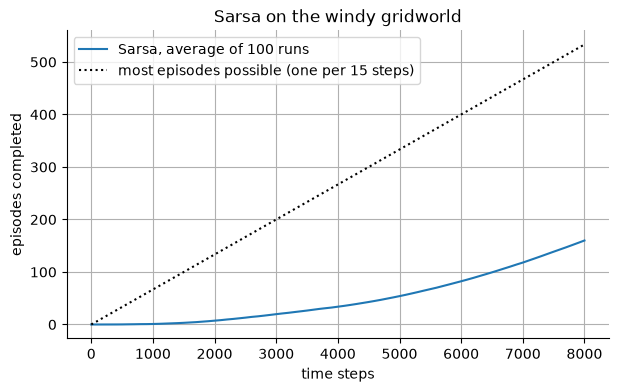

In [27]:
z_dur = (late[:, 0].mean() - long_late[ALPHA_CONTROL][:, 0].mean()) / np.hypot(
    late_se, long_late[ALPHA_CONTROL][:, 0].std(ddof=1) / np.sqrt(WINDY_LONG_RUNS)
)
z_small = (final_episodes.mean() - small_episodes.mean()) / np.hypot(
    final_episodes.std(ddof=1) / np.sqrt(WINDY_RUNS), small_episodes.std(ddof=1) / np.sqrt(WINDY_LONG_RUNS)
)
z_wind = bonferroni_z(PAIR)
check(
    f"no Sarsa episode is shorter than the {WINDY_MIN_STEPS}-step shortest path, and {WINDY_MIN_STEPS} is reached",
    all_lengths.min() == bfs_len,
)
check(
    f"episodes completed never exceed time steps divided by {WINDY_MIN_STEPS} (the shortest path)",
    (episodes_by_t <= grid_t // bfs_len).all(),
)
check(
    f"sanity bound, which any learner passes: no run's late average length is below the best {EPS}-greedy policy's {soft_len:.2f} by more than {bonferroni_z(WINDY_RUNS):.2f} standard errors",
    z_low.min() > -bonferroni_z(WINDY_RUNS),
)
check(
    f"training duration matters: with alpha = {ALPHA_CONTROL}, late episodes after {WINDY_LONG_STEPS} steps are shorter than after {WINDY_STEPS} (z = {z_dur:.1f}, limit {z_wind:.2f})",
    z_dur > z_wind,
)
check(
    f"with alpha = {WINDY_SMALL_ALPHA}, fewer episodes are completed in {WINDY_STEPS} steps than with alpha = {ALPHA_CONTROL} (z = {z_small:.1f}, limit {z_wind:.2f})",
    z_small > z_wind,
)

plt.plot(grid_t, episodes_by_t.mean(axis=0), label=f"Sarsa, average of {WINDY_RUNS} runs")
plt.plot(grid_t, grid_t / bfs_len, "k:", label=f"most episodes possible (one per {bfs_len} steps)")
plt.xlabel("time steps")
plt.ylabel("episodes completed")
plt.title("Sarsa on the windy gridworld")
plt.legend()
plt.show()

### Reading the result

- **Truth.** Breadth-first search and value iteration both give 15 steps, the book's minimum. The best exploring ($\varepsilon = 0.1$) policy needs 17.048 steps on average, which is the number the book's "about 17" matches.
- **Learning curve.** Averaged over 100 runs, Sarsa has completed 1.0, 7.3, 33.9, 82.3 and 160.0 episodes after 1000, 2000, 4000, 6000 and 8000 time steps (standard errors 0.1 to 1.0). The slope rises over time, as in the book. The book's single run (by eye: about 78 episodes at 6000 steps and 170 at about 7850) sits about one standard deviation above the mean at 8000 steps (standard deviation over runs 9.6; 12 of 100 runs reach 170), so one run like it is unremarkable.
- **Plot.** The curve of completed episodes bends upward as episodes get shorter and stays below the dotted line of the most episodes possible, one per 15 steps.
- **Hard bounds hold.** The shortest of all episodes is 15 steps, and the number of completed episodes never exceeds time steps divided by 15.
- **Disagreement with the book.** The notebook does not reproduce "about 17 steps" or "long since optimal" at 8000 steps with $\alpha = 0.5$. Episodes that end after step 6000 average 26.03 steps (standard error 0.24 over runs; the best single run averages 21.16), far from the exact 17.05. The book's own figure implies about 20 steps per episode late on (by eye, 92 episodes in about 1850 steps), which is also above 17; here 77.7 episodes are completed between 6000 and 8000 steps, about 25.7 steps each.
- **What drives the gap (measured).** With $\alpha = 0.5$ and 100,000 steps the late average (after step 75,000) is 18.96 (standard error 0.11 over 10 runs), and with $\alpha = 0.1$ it is 17.17 (0.03). So training duration is the main factor: the large step size costs about 1.9 steps over the exact 17.05 even after a long run, and a small step size costs only 0.12, but with $\alpha = 0.1$ the 8000-step runs complete only 26.9 episodes (standard error 0.2) against 160.0, because learning is far slower.
- **Greedy policy.** At 8000 steps with $\alpha = 0.5$ the greedy path from the start is a shortest path (15 steps) in only 14 of 100 runs; it reaches the goal in 51 runs (lengths 15 to 23) and never reaches the goal in 49. None of the 49 stuck rollouts has an exact tie on its path, so the tie-break rule (lowest-numbered action) is not the cause; the loops come from strict near-ties: along the path the smallest gap between the best and second-best action value has median 0.018 and maximum 0.124. The action values are simply not converged at 8000 steps (that they are noisy and slow to settle is consistent with the long runs below, but not tested separately). The exploring agent itself still finishes episodes. The first map is the greedy path of run 3 (16 steps); the second is run 0, which is stuck (it moves right three cells, then stays).
- **Long runs.** With $\alpha = 0.1$ and 100,000 steps all 10 greedy paths have 15 steps; with $\alpha = 0.5$ and 100,000 steps they are [15, 500, 15, 16, 15, 15, 15, 16, 17, 17], where 500 marks one stuck rollout.
- Sarsa learns during the episodes, so no episode ever has to end by itself: that is the property the book gives for preferring it to MC here, and it is not tested.

## 6. Q-learning against Sarsa on the cliff

A $4 \times 12$ grid, start at the bottom left $(3, 0)$, goal at the bottom right $(3, 11)$, and the cells between them are a cliff. Reward is $-1$ per step, but stepping into the cliff costs $-100$ and sends the agent back to the start (the episode continues). Both methods act $\varepsilon$-greedily with $\varepsilon = 0.1$. The book gives only $\varepsilon$; $\alpha = 0.5$ and $Q = 0$ initially are choices made here (the values of the windy gridworld).

**Q-learning** changes only the target: the best next action instead of the next action actually taken,

$$
Q(S_t, A_t) \leftarrow Q(S_t, A_t) + \alpha\big[R_{t+1} + \gamma \max_a Q(S_{t+1}, a) - Q(S_t, A_t)\big].
$$

- Q-learning estimates the optimal action values $q_*$ whatever policy is followed, so it learns the path along the cliff edge. Sarsa estimates the values of the exploring policy itself, which includes the occasional random step into the cliff, so it values the edge lower.
- First, the off-policy claim (learning the values of one policy, here the optimal one, while following another) on a small deterministic gridworld (4 rows by 5 columns, no wind, no cliff, start bottom left, goal top right): Q-learning run on a purely random behavior ($\varepsilon = 1$) with $\alpha = 1$ should land exactly on the optimal action values.
- Then the book's task: reward per episode while learning (online performance), then the greedy policy each method ends with. 50 runs are averaged (the book shows one smoothed run), each pair of runs (Sarsa and Q-learning) starts from the same seed, but their random draws diverge as soon as their choices differ, so the runs are not paired in effect.
- Truths from other routes (value iteration and exact policy evaluation): the optimal values $q_*$; the best $\varepsilon$-greedy policy, which is what Sarsa converges to; and what the $\varepsilon$-greedy policy built on $q_*$ earns while exploring, which is what Q-learning's online reward settles at if its values are exact.
- Number of falls per episode is recovered from the reward and the length: a fall replaces a $-1$ by $-100$, so falls = (−return − length) / 99.

In [28]:
t_env = grid_world(TINY_SHAPE, (0,) * TINY_SHAPE[1], TINY_START, TINY_GOAL)
t_nxt, t_rew, t_start, t_goal = t_env
q_tiny = soft_optimal_q(t_nxt, t_rew, t_goal, 0.0)
q_rand, lens_rand, _, _ = td_control(
    t_env,
    np.random.default_rng(SEED_QTEST),
    eps=1.0,
    alpha=1.0,
    q_learning=True,
    max_steps=QTEST_STEPS,
)
not_goal = np.arange(len(t_nxt)) != t_goal
err_rand = np.abs(q_rand - q_tiny)[not_goal].max()
v_random = policy_value(t_nxt, t_rew, t_goal, np.full(t_nxt.shape, 1 / t_nxt.shape[1]))
gap_random = np.abs(t_rew + v_random[t_nxt] - q_tiny)[not_goal].mean()
print(
    f"Q-learning on a purely random behavior ({QTEST_STEPS} steps, {len(lens_rand)} episodes), alpha = 1: largest error against q* over the {int(not_goal.sum()) * 4} non-goal pairs is {err_rand:.1e}"
)
print(
    f"For contrast, the values of the random policy itself (what Sarsa would estimate) differ from q* by {gap_random:.1f} on average"
)
check(
    f"Q-learning on purely random behavior reproduces q* on every pair to within {ROUNDING_TOL:.0e} (the environment is deterministic and alpha = 1)",
    err_rand < ROUNDING_TOL,
)

Q-learning on a purely random behavior (50000 steps, 612 episodes), alpha = 1: largest error against q* over the 76 non-goal pairs is 0.0e+00
For contrast, the values of the random policy itself (what Sarsa would estimate) differ from q* by 62.1 on average
Checkpoint: Q-learning on purely random behavior reproduces q* on every pair to within 1e-10 (the environment is deterministic and alpha = 1): True


In [29]:
c_env = grid_world(CLIFF_SHAPE, (0,) * CLIFF_SHAPE[1], CLIFF_START, CLIFF_GOAL, CLIFF_CELLS)
c_nxt, c_rew, c_start, c_goal = c_env
falls_table = (c_rew == CLIFF_PENALTY).astype(float)
q_star_c = soft_optimal_q(c_nxt, c_rew, c_goal, 0.0)
q_soft_c = soft_optimal_q(c_nxt, c_rew, c_goal, EPS)
exact = {}
for name, q in (("edge (epsilon-greedy on q*)", q_star_c), ("best epsilon-greedy", q_soft_c)):
    probs = eps_greedy_probs(q, EPS)
    exact[name] = (
        policy_value(c_nxt, c_rew, c_goal, probs)[c_start],
        policy_value(c_nxt, falls_table, c_goal, probs)[c_start],
    )
v_edge, v_soft = exact["edge (epsilon-greedy on q*)"][0], exact["best epsilon-greedy"][0]
bfs_c = shortest_steps(c_nxt, c_rew, c_start, c_goal)
path_star, _ = greedy_rollout(c_nxt, c_rew, c_start, c_goal, q_star_c)
path_soft, ret_soft = greedy_rollout(c_nxt, c_rew, c_start, c_goal, q_soft_c)
print(
    f"Shortest path avoiding the cliff (breadth-first search): {bfs_c} steps; optimal value of the start (value iteration): {q_star_c.max(1)[c_start]:.0f}"
)
for name, (v, f) in exact.items():
    print(f"Exact, played with epsilon = {EPS}: {name}: return per episode {v:.3f}, falls per episode {f:.3f}")
print(
    f"Greedy path of the best epsilon-greedy policy: {len(path_soft) - 1} steps, return {ret_soft:.0f}; its map:\n"
    + draw_path(path_soft, CLIFF_SHAPE, c_start, c_goal, CLIFF_CELLS)
)
check(
    "breadth-first search and value iteration agree on the 13-step optimal path along the cliff edge",
    bfs_c == -q_star_c.max(1)[c_start] == CLIFF_MIN_STEPS == len(path_star) - 1,
)
check(
    "played with exploration, the edge policy earns less than the best epsilon-greedy policy, which takes a longer path",
    v_soft > v_edge and len(path_soft) - 1 > bfs_c,
)

Shortest path avoiding the cliff (breadth-first search): 13 steps; optimal value of the start (value iteration): -13
Exact, played with epsilon = 0.1: edge (epsilon-greedy on q*): return per episode -50.800, falls per episode 0.342
Exact, played with epsilon = 0.1: best epsilon-greedy: return per episode -20.708, falls per episode 0.036
Greedy path of the best epsilon-greedy policy: 15 steps, return -15; its map:
............
************
*..........*
SXXXXXXXXXXG
Checkpoint: breadth-first search and value iteration agree on the 13-step optimal path along the cliff edge: True
Checkpoint: played with exploration, the edge policy earns less than the best epsilon-greedy policy, which takes a longer path: True


In [30]:
seeds = np.random.SeedSequence(SEED_CLIFF).spawn(CLIFF_RUNS)
sarsa_runs = [
    td_control(c_env, np.random.default_rng(s), EPS, ALPHA_CONTROL, max_episodes=CLIFF_EPISODES) for s in seeds
]
qlearn_runs = [
    td_control(
        c_env,
        np.random.default_rng(s),
        EPS,
        ALPHA_CONTROL,
        q_learning=True,
        max_episodes=CLIFF_EPISODES,
    )
    for s in seeds
]
ret = {"Sarsa": np.array([r[2] for r in sarsa_runs]), "Q-learning": np.array([r[2] for r in qlearn_runs])}
fall = {
    name: np.array(
        [
            [(-r - l) / FALL_COST for l, r in zip(run[1], run[2])]
            for run in (sarsa_runs if name == "Sarsa" else qlearn_runs)
        ]
    )
    for name in ret
}

In [31]:
late_ret = {name: r[:, CLIFF_LATE_FROM:].mean(axis=1) for name, r in ret.items()}
se = {name: x.std(ddof=1) / np.sqrt(CLIFF_RUNS) for name, x in late_ret.items()}
z_online = (late_ret["Sarsa"].mean() - late_ret["Q-learning"].mean()) / np.hypot(se["Sarsa"], se["Q-learning"])
for name in ret:
    print(
        f"{name:>10}: online reward per episode, episodes {CLIFF_LATE_FROM + 1}-{CLIFF_EPISODES}: {late_ret[name].mean():.2f}±{se[name]:.2f}; falls per episode {fall[name][:, CLIFF_LATE_FROM:].mean():.3f}"
    )
for name, runs in (("Sarsa", sarsa_runs), ("Q-learning", qlearn_runs)):
    steps = np.mean([np.mean(r[1][CLIFF_LATE_FROM:]) for r in runs])
    print(
        f"{name:>10}: steps per episode {steps:.2f}; the falls cost {FALL_COST * fall[name][:, CLIFF_LATE_FROM:].mean():.2f} of reward per episode beyond the -1 per step"
    )
print(
    f"Difference Sarsa - Q-learning in online reward: {late_ret['Sarsa'].mean() - late_ret['Q-learning'].mean():.2f} (z = {z_online:.1f})"
)

     Sarsa: online reward per episode, episodes 101-500: -27.22±0.42; falls per episode 0.051
Q-learning: online reward per episode, episodes 101-500: -50.22±0.56; falls per episode 0.335
     Sarsa: steps per episode 22.19; the falls cost 5.02 of reward per episode beyond the -1 per step
Q-learning: steps per episode 17.08; the falls cost 33.14 of reward per episode beyond the -1 per step
Difference Sarsa - Q-learning in online reward: 23.00 (z = 32.8)


In [32]:
greedy = {}
for name, runs in (("Sarsa", sarsa_runs), ("Q-learning", qlearn_runs)):
    rolls = [greedy_rollout(c_nxt, c_rew, c_start, c_goal, r[0]) for r in runs]
    explore = np.array([policy_value(c_nxt, c_rew, c_goal, eps_greedy_probs(r[0], EPS))[c_start] for r in runs])
    greedy[name] = (rolls, explore)
    outcomes = ["stuck" if g is None else int(g) for _, g in rolls]
    top_rows = ["stuck" if g is None else min(s // CLIFF_SHAPE[1] for s in p) for p, g in rolls]
    print(
        f"{name:>10}: greedy return, runs per value: {dict(Counter(outcomes))}; highest row reached: {dict(Counter(top_rows))}; exact exploring return of the same policies, median {np.median(explore):.2f}"
    )
print(
    "Q-learning, run 0 greedy path:\n"
    + draw_path(greedy["Q-learning"][0][0][0], CLIFF_SHAPE, c_start, c_goal, CLIFF_CELLS)
)
print("Sarsa, run 0 greedy path:\n" + draw_path(greedy["Sarsa"][0][0][0], CLIFF_SHAPE, c_start, c_goal, CLIFF_CELLS))

     Sarsa: greedy return, runs per value: {-17: 40, 'stuck': 8, -19: 2}; highest row reached: {0: 42, 'stuck': 8}; exact exploring return of the same policies, median -22.59
Q-learning: greedy return, runs per value: {-13: 50}; highest row reached: {2: 50}; exact exploring return of the same policies, median -50.60
Q-learning, run 0 greedy path:
............
............
************
SXXXXXXXXXXG
Sarsa, run 0 greedy path:
.**********.
**........*.
*.........**
SXXXXXXXXXXG


Checkpoint: Sarsa earns more reward while learning than Q-learning (z = 32.8, limit 1.96): True
Checkpoint: Q-learning's online reward is at the exact exploring value of the edge policy, within 2.39 standard errors (the converged values would give exactly this): True
Checkpoint: Sarsa's online reward does not beat the best epsilon-greedy policy's exact value, within 2.39 standard errors (a bound, not a match): True
Checkpoint: every Q-learning run ends with the 13-step edge path as its greedy policy: True
Checkpoint: the Q-learning policies, played with exploration, earn on average the exact edge value within 2.39 standard errors: True
Checkpoint: Sarsa's greedy policies, played with exploration, earn more than Q-learning's in the median run: True


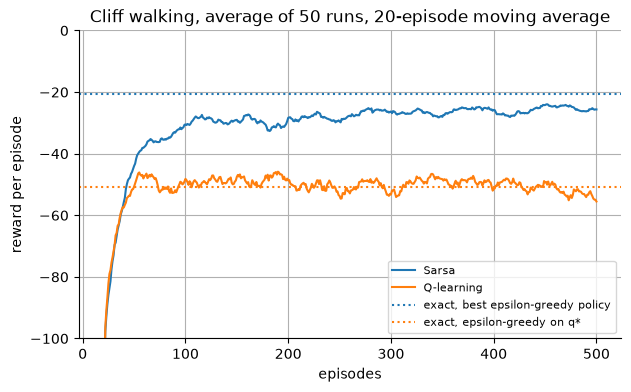

In [33]:
z_one = bonferroni_z(SINGLE)
check(
    f"Sarsa earns more reward while learning than Q-learning (z = {z_online:.1f}, limit {z_one:.2f})", z_online > z_one
)
z_exact = bonferroni_z(CLIFF_EXACT_CHECKS)
q_explore = greedy["Q-learning"][1]
check(
    f"Q-learning's online reward is at the exact exploring value of the edge policy, within {z_exact:.2f} standard errors (the converged values would give exactly this)",
    abs(late_ret["Q-learning"].mean() - v_edge) < z_exact * se["Q-learning"],
)
check(
    f"Sarsa's online reward does not beat the best epsilon-greedy policy's exact value, within {z_exact:.2f} standard errors (a bound, not a match)",
    late_ret["Sarsa"].mean() < v_soft + z_exact * se["Sarsa"],
)
check(
    f"every Q-learning run ends with the {CLIFF_MIN_STEPS}-step edge path as its greedy policy",
    all(g == -CLIFF_MIN_STEPS for _, g in greedy["Q-learning"][0]),
)
check(
    f"the Q-learning policies, played with exploration, earn on average the exact edge value within {z_exact:.2f} standard errors",
    abs(q_explore.mean() - v_edge) < z_exact * q_explore.std(ddof=1) / np.sqrt(CLIFF_RUNS),
)
check(
    "Sarsa's greedy policies, played with exploration, earn more than Q-learning's in the median run",
    np.median(greedy["Sarsa"][1]) > np.median(greedy["Q-learning"][1]),
)

kernel = np.ones(SMOOTH) / SMOOTH
for name, r in ret.items():
    plt.plot(np.arange(SMOOTH, CLIFF_EPISODES + 1), np.convolve(r.mean(axis=0), kernel, mode="valid"), label=name)
plt.axhline(v_soft, color="C0", ls=":", label="exact, best epsilon-greedy policy")
plt.axhline(v_edge, color="C1", ls=":", label="exact, epsilon-greedy on q*")
plt.ylim(-100, 0)
plt.xlabel("episodes")
plt.ylabel("reward per episode")
plt.title(f"Cliff walking, average of {CLIFF_RUNS} runs, {SMOOTH}-episode moving average")
plt.legend(fontsize=8)
plt.show()

### Reading the result

- **Off-policy claim.** On the small gridworld, Q-learning that acts completely at random ($\varepsilon = 1$) for 50,000 steps (612 episodes) with $\alpha = 1$ matches the optimal action values on all 76 non-goal pairs exactly (largest error 0). The values of the random policy itself, which is what Sarsa would estimate under that behavior, differ from the optimal ones by 62.1 on average, so the match is not automatic.
- **Exact answers on the cliff.** The shortest path avoiding the cliff has 13 steps (breadth-first search and value iteration agree). Played with $\varepsilon = 0.1$, the policy that is $\varepsilon$-greedy with respect to the optimal values earns -50.800 per episode with 0.342 falls per episode, while the best $\varepsilon$-greedy policy earns -20.708 with 0.036 falls; its greedy path has 15 steps (the map above: up two rows, along the second row, down).
- **Online reward.** Over episodes 101 to 500 and 50 runs, Sarsa earns -27.22 (standard error 0.42) and Q-learning -50.22 (0.56) per episode; the difference of 23.00 has $z = 32.8$. Q-learning's value is within the limit of 2.39 standard errors (three comparisons judged together) of the exact -50.800 for the edge policy; Sarsa's is below the exact best of -20.708, as it must be (that check is a bound, not a match).
- **Why (computed).** Q-learning's episodes are shorter (17.08 steps against 22.19) but it falls 0.335 times per episode against 0.051, which costs 33.14 of reward against 5.02 beyond the -1 per step; the exact falls of the two target policies (0.342 and 0.036) are close to these. Q-learning's values are those of the edge path, whose exploring version walks next to the cliff; Sarsa's values include the exploring steps, so they favor staying away.
- **Plot.** Both curves start near -100 and rise within roughly the first 40 episodes (by eye). Afterwards Sarsa's curve stays about 6.5 below its dotted line (-27.22 against -20.708) and Q-learning's stays close to its dotted line (-50.22 against -50.800).
- **Greedy policies.** All 50 Q-learning runs end with the 13-step edge path as their greedy policy (return -13). Sarsa's greedy policy is the 17-step path along the top row in 40 runs, a 19-step path in 2 runs and has a greedy rollout that never reaches the goal in 8 runs. Played with exploration, the exact return of the learned policies is -50.60 (median) for Q-learning and -22.59 for Sarsa: the greedy policy that is best without exploration is much worse with it.
- **Book.** The result agrees: the book's plot shows Sarsa near -25 and Q-learning near -50 (by eye), the optimal edge path for Q-learning and a longer safe path along the top for Sarsa. Not in the book: the exact best exploring policy takes the second row (15 steps), not the top row, so Sarsa with $\alpha = 0.5$ ends on a path that is safer than the exact optimum for exploring; the reason is not tested.

## 7. Checkpoints

In [34]:
for claim, ok in CHECKS:
    print(("PASS " if ok else "FAIL ") + claim)
assert all(ok for _, ok in CHECKS)

PASS TD and MC errors equal the hand arithmetic from the book's table
PASS the book's quoted MC error at the highway exit is 8 and its alpha = 1/2 update is +4
PASS the TD errors from step t on sum to the MC error at step t (identity for gamma = 1, not an independent test)
PASS the online TD(0) loop and the vectorized TD errors agree (consistency of two code paths)
PASS the TD update is available after one step: with the jam the start's estimate rises from 30 toward 50 (arithmetic of the update rule)
PASS the simulated walk, the TD error and the first-visit MC error are unbiased at the truth (12 comparisons, Bonferroni limit 2.87)
PASS TD (best alpha) beats MC (best alpha) at every compared episode count by more than 2.50 paired standard errors
PASS after 100 episodes every one of the 12 TD step sizes is below every MC step size (paired z above 2.87)
PASS batch TD(0) reaches the certainty-equivalence estimate and batch MC the sample averages, in every run, within the derived bounds
PAS

In [35]:
print(
    "\nThe reference is the book's number or an exact value, except where marked 'bound' (a limit the result cannot beat) or 'zero' (a perfect estimate)."
)
print(f"{'quantity':<70}{'result':>9}{'reference':>10}")
for name, result, reference in [
    ("driving home: MC error at the highway exit, minutes (book)", f"{mc_error[2]:.0f}", "8"),
    (
        f"random walk: RMS error after {WALK_EPISODES} episodes, {best_td} (zero)",
        f"{curves[best_td][:, WALK_EPISODES].mean():.4f}",
        "0",
    ),
    (
        f"random walk: RMS error after {WALK_EPISODES} episodes, {best_mc} (zero)",
        f"{curves[best_mc][:, WALK_EPISODES].mean():.4f}",
        "0",
    ),
    (f"batch: RMS error after {BATCH_EPISODES} episodes, TD(0) (zero)", f"{err_td[:, BATCH_EPISODES].mean():.4f}", "0"),
    (f"batch: RMS error after {BATCH_EPISODES} episodes, MC (zero)", f"{err_mc[:, BATCH_EPISODES].mean():.4f}", "0"),
    ("predictor: V(A) from batch TD(0) (exact model value)", f"{td_vals[0, 0]:.4f}", f"{PRED_P_RIGHT:.4f}"),
    ("predictor: V(A) from batch MC (sample average)", f"{mc_vals[0, 0]:.4f}", "0.0000"),
    ("windy gridworld: shortest Sarsa episode, steps (exact)", f"{all_lengths.min()}", f"{bfs_len}"),
    (
        f"windy gridworld: late episode length, alpha = {ALPHA_CONTROL}, {WINDY_STEPS} steps (bound)",
        f"{late[:, 0].mean():.2f}",
        f"{soft_len:.2f}",
    ),
    (
        f"windy gridworld: late episode length, alpha = {WINDY_LONG_ALPHAS[0]}, {WINDY_LONG_STEPS} steps (bound)",
        f"{long_late[WINDY_LONG_ALPHAS[0]][:, 0].mean():.2f}",
        f"{soft_len:.2f}",
    ),
    (
        f"windy gridworld: late episode length, alpha = {ALPHA_CONTROL}, {WINDY_LONG_STEPS} steps (bound)",
        f"{long_late[ALPHA_CONTROL][:, 0].mean():.2f}",
        f"{soft_len:.2f}",
    ),
    ("cliff: Sarsa online reward per episode (bound)", f"{late_ret['Sarsa'].mean():.2f}", f"{v_soft:.2f}"),
    ("cliff: Q-learning online reward per episode (exact)", f"{late_ret['Q-learning'].mean():.2f}", f"{v_edge:.2f}"),
    (
        "cliff: Q-learning greedy return, worst run (exact)",
        f"{min(g for _, g in greedy['Q-learning'][0]):.0f}",
        f"{-CLIFF_MIN_STEPS}",
    ),
]:
    print(f"{name:<70}{result:>9}{reference:>10}")


The reference is the book's number or an exact value, except where marked 'bound' (a limit the result cannot beat) or 'zero' (a perfect estimate).
quantity                                                                 result reference
driving home: MC error at the highway exit, minutes (book)                    8         8
random walk: RMS error after 100 episodes, TD alpha=0.1 (zero)           0.0547         0
random walk: RMS error after 100 episodes, MC alpha=0.03 (zero)          0.0965         0
batch: RMS error after 100 episodes, TD(0) (zero)                        0.0419         0
batch: RMS error after 100 episodes, MC (zero)                           0.0599         0
predictor: V(A) from batch TD(0) (exact model value)                     0.7500    0.7500
predictor: V(A) from batch MC (sample average)                           0.0000    0.0000
windy gridworld: shortest Sarsa episode, steps (exact)                       15        15
windy gridworld: late episode length, alph